# **Universidad de Buenos Aires**
# CEIA - Aprendizaje por Refuerzo I
# Tema: SARSA y Q-Learning en CliffWalking
---
# Trabajo Práctico 2

De acuerdo a la siguiente celda resolver y responder las preguntas modificando el código original y reescribiéndolo luego de cada pregunta.


(En esta celda se implementan los algoritmos **SARSA** y **Q-Learning** originales de Sutton & Barto, aplicados al entorno **CliffWalking** de `gymnasium`, y se comparan sus resultados. A lo largo del TP se irán realizando ajustes progresivos hasta lograr que ambos aprendan una política satisfactoria.)

Ep 50 | ε=0.300 | SARSA (últ. 50): -176.5 | Q-Learning (últ. 50): -284.3
Ep 100 | ε=0.300 | SARSA (últ. 50): -46.1 | Q-Learning (últ. 50): -149.5
Ep 150 | ε=0.300 | SARSA (últ. 50): -54.5 | Q-Learning (últ. 50): -228.6
Ep 200 | ε=0.300 | SARSA (últ. 50): -73.6 | Q-Learning (últ. 50): -150.4
Ep 250 | ε=0.300 | SARSA (últ. 50): -118.5 | Q-Learning (últ. 50): -184.1
Ep 300 | ε=0.300 | SARSA (últ. 50): -59.4 | Q-Learning (últ. 50): -195.0
Ep 350 | ε=0.300 | SARSA (últ. 50): -58.7 | Q-Learning (últ. 50): -218.0
Ep 400 | ε=0.300 | SARSA (últ. 50): -58.7 | Q-Learning (últ. 50): -152.9
Ep 450 | ε=0.300 | SARSA (últ. 50): -81.8 | Q-Learning (últ. 50): -157.2
Ep 500 | ε=0.300 | SARSA (últ. 50): -50.0 | Q-Learning (últ. 50): -168.0


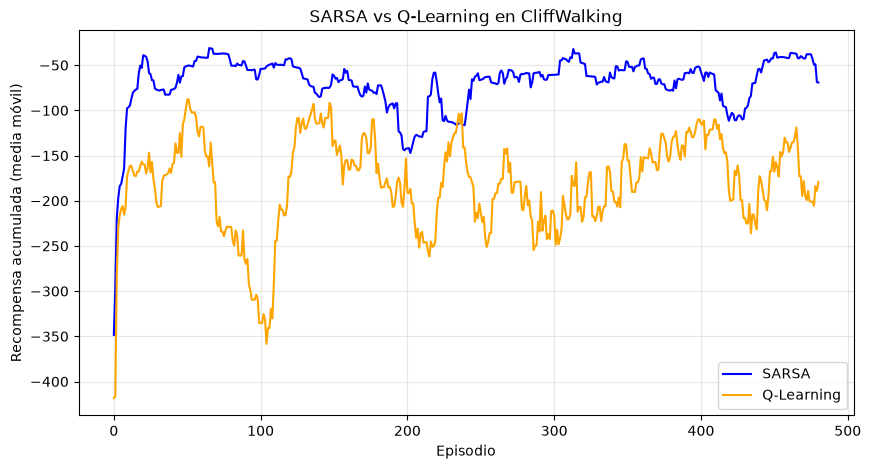


✅ Recompensa de la política final SARSA:      -200.0
✅ Recompensa de la política final Q-Learning: -13.0

Política aprendida — SARSA (↑ 0, → 1, ↓ 2, ← 3):
→ → ↑ ↑ → → ↓ → ↑ ↓ ← ← 
↑ → ↑ ↑ → ↑ → → → → ↑ ↓ 
↑ ↑ ↑ ↑ ↑ ↑ ↑ → ↑ ↑ → ↓ 
🤖 💧 💧 💧 💧 💧 💧 💧 💧 💧 💧 🎯 

Política aprendida — Q-Learning (↑ 0, → 1, ↓ 2, ← 3):
→ ↓ → → ↓ → ↓ → ↓ → ↓ ↓ 
↓ → → → → → → → → → → ↓ 
→ → → → → → → → → → → ↓ 
🤖 💧 💧 💧 💧 💧 💧 💧 💧 💧 💧 🎯 


In [1]:
# ============================================================
# Celda 1: Instalación e imports
# ============================================================
!pip install gymnasium matplotlib numpy -q

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ============================================================
# Celda 2: Entorno y parámetros
# ============================================================
env = gym.make('CliffWalking-v1')

N_STATES = env.observation_space.n     # 48 estados (grilla 4x12)
N_ACTIONS = env.action_space.n         # 4 acciones: 0 arriba, 1 derecha, 2 abajo, 3 izquierda

NUM_EPISODES = 500
ALPHA = 0.5
GAMMA = 1.0
EPSILON = 0.3   # epsilon CONSTANTE (sin decaimiento) durante todo el entrenamiento

# ============================================================
# Celda 3: Inicialización de las tablas Q
# ============================================================
Q_sarsa = np.zeros((N_STATES, N_ACTIONS))
Q_qlearning = np.zeros((N_STATES, N_ACTIONS))

# ============================================================
# Celda 4: Política de comportamiento epsilon-greedy (común a ambos)
# ============================================================
def epsilon_greedy(Q, state, epsilon):
    if np.random.rand() < epsilon:
        return np.random.randint(N_ACTIONS)
    return int(np.argmax(Q[state]))

def greedy(Q, state):
    return int(np.argmax(Q[state]))

# ============================================================
# Celda 5: Algoritmo SARSA (on-policy, Sutton & Barto)
# ============================================================
def run_sarsa_episode(Q, alpha, gamma, epsilon):
    state, _ = env.reset()
    action = epsilon_greedy(Q, state, epsilon)
    total_reward = 0
    done = False
    while not done:
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        next_action = epsilon_greedy(Q, next_state, epsilon)

        # Actualización SARSA: usa la acción REALMENTE tomada en s' (on-policy)
        Q[state][action] += alpha * (
            reward + gamma * Q[next_state][next_action] - Q[state][action]
        )

        state, action = next_state, next_action
        total_reward += reward
    return total_reward

# ============================================================
# Celda 6: Algoritmo Q-Learning (off-policy, Sutton & Barto)
# ============================================================
def run_qlearning_episode(Q, alpha, gamma, epsilon):
    state, _ = env.reset()
    total_reward = 0
    done = False
    while not done:
        action = epsilon_greedy(Q, state, epsilon)
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated

        # Actualización Q-Learning: usa el máximo sobre s' (off-policy)
        best_next = np.max(Q[next_state])
        Q[state][action] += alpha * (
            reward + gamma * best_next - Q[state][action]
        )

        state = next_state
        total_reward += reward
    return total_reward

# ============================================================
# Celda 7: Entrenamiento de ambos agentes
# ============================================================
rewards_sarsa = []
rewards_qlearning = []
epsilon = EPSILON

for ep in range(NUM_EPISODES):
    r_sarsa = run_sarsa_episode(Q_sarsa, ALPHA, GAMMA, epsilon)
    r_qlearning = run_qlearning_episode(Q_qlearning, ALPHA, GAMMA, epsilon)

    rewards_sarsa.append(r_sarsa)
    rewards_qlearning.append(r_qlearning)

    if (ep + 1) % 50 == 0:
        avg_s = np.mean(rewards_sarsa[-50:])
        avg_q = np.mean(rewards_qlearning[-50:])
        print(f"Ep {ep+1} | ε={epsilon:.3f} | SARSA (últ. 50): {avg_s:.1f} | Q-Learning (últ. 50): {avg_q:.1f}")

# ============================================================
# Celda 8: Visualización comparativa
# ============================================================
def moving_average(x, w=20):
    return np.convolve(x, np.ones(w) / w, mode='valid')

plt.figure(figsize=(10, 5))
plt.plot(moving_average(rewards_sarsa), color='blue', label='SARSA')
plt.plot(moving_average(rewards_qlearning), color='orange', label='Q-Learning')
plt.xlabel('Episodio')
plt.ylabel('Recompensa acumulada (media móvil)')
plt.title('SARSA vs Q-Learning en CliffWalking')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ============================================================
# Celda 9: Evaluación y políticas finales
# ============================================================
def evaluate_policy(Q, n_eval=1, max_steps=200):
    """Ejecuta la política greedy (100% explotación) y devuelve la recompensa total."""
    total = 0
    for _ in range(n_eval):
        state, _ = env.reset()
        done = False
        steps = 0
        while not done and steps < max_steps:
            action = greedy(Q, state)
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total += reward
            steps += 1
    return total / n_eval

print(f"\n✅ Recompensa de la política final SARSA:      {evaluate_policy(Q_sarsa):.1f}")
print(f"✅ Recompensa de la política final Q-Learning: {evaluate_policy(Q_qlearning):.1f}")

ARROWS = {0: '↑', 1: '→', 2: '↓', 3: '←'}
N_ROWS, N_COLS = 4, 12
CLIFF = set(range(37, 47))  # fila inferior, entre el inicio (36) y la meta (47)
START, GOAL = 36, 47

def print_policy(Q, name):
    print(f"\nPolítica aprendida — {name} (↑ 0, → 1, ↓ 2, ← 3):")
    for row in range(N_ROWS):
        line = ""
        for col in range(N_COLS):
            s = row * N_COLS + col
            if s == START:
                line += "🤖 "
            elif s == GOAL:
                line += "🎯 "
            elif s in CLIFF:
                line += "💧 "
            else:
                line += ARROWS[greedy(Q, s)] + " "
        print(line)

print_policy(Q_sarsa, "SARSA")
print_policy(Q_qlearning, "Q-Learning")

## Preparación para resolver las preguntas

En cada pregunta el código original se reescribe como una función que entrena una corrida completa de los dos agentes a partir de una semilla, con la misma lógica de las celdas 2 a 7: en cada episodio de entrenamiento juega primero SARSA y después Q learning, con el mismo generador de números al azar, como en el original. Con la semilla 42 la función reproduce exactamente la celda de arriba: las medias por bloques de 50 episodios y la evaluación final (−200 para SARSA y −13 para Q learning) son las mismas. Esta celda define lo que comparten todas las preguntas: la selección del dispositivo, las semillas, la evaluación greedy de la celda 9, la ejecución en paralelo, las tablas, la impresión de las tablas Q y de las políticas, y unos valores de referencia.

Tres ejecuciones y treinta semillas. La consigna pide ejecutar 3 veces cada celda modificada. Las 3 ejecuciones son las semillas 42, 43 y 44, y aparecen por separado en cada tabla (ejec 1, ejec 2 y ejec 3) y en los gráficos. CliffWalking es determinista, así que todo el azar viene de la exploración ε greedy, y aun así el resultado cambia mucho de una semilla a otra: con el código original la política greedy de SARSA da −200, −17 y −19 en las 3 ejecuciones y llega a la meta solo en 13 de 30 semillas. Por eso cada configuración se entrena además con 30 semillas, que incluyen a esas 3, y las conclusiones se basan en la media de las 30 y su error estándar (ee). Es barato: las 30 corridas de la configuración original tardan 2 segundos.

Dispositivo. Se prefiere la GPU cuando el cálculo es tensorial, pero en este TP no conviene: las tablas Q son de 48 por 4 y gymnasium simula CliffWalking en CPU un paso por vez, así que cada decisión ε greedy es una consulta chica y secuencial. La celda lo mide: en esta ejecución una consulta greedy sobre una fila de Q tardó 0.6 µs en la CPU y 24.0 µs en la GPU, unas 40 veces más, mientras que un paso del entorno, que siempre corre en CPU, tardó 3.1 µs. Lo que sí acelera es correr en paralelo las semillas y configuraciones, que son independientes, en los 32 hilos de la CPU con joblib.

Referencias. Para leer las tablas Q se calculan dos valores de referencia con el modelo del entorno, que los agentes no usan. Q* se obtiene por iteración de valor (Programación dinámica, págs. 71 a 73) y es el valor al que apunta Q learning, que aprende el valor de la política greedy. El otro es el valor de la mejor política ε greedy para un ε fijo, que es lo que aprende SARSA porque evalúa la política que ejecuta, exploración incluida (Métodos de diferencia temporal, págs. 39 y 42). Se calcula igual que Q*, pero en lugar del máximo sobre las acciones del estado siguiente se usa el promedio con las probabilidades de la política ε greedy.

In [2]:
# ============================================================
# Preparación: dispositivo, semillas y utilidades comunes
# ============================================================
import os
import platform
import time
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

try:
    from joblib import Parallel, delayed
except ImportError:
    %pip install joblib -q
    from joblib import Parallel, delayed

plt.style.use('dark_background')

SEMILLAS = list(range(42, 72))   # 30 corridas por configuración
N_EJECUCIONES = 3                # las 3 primeras semillas son las 3 ejecuciones pedidas
N_STATES, N_ACTIONS = 48, 4
N_ROWS, N_COLS = 4, 12
START, GOAL = 36, 47
CLIFF = set(range(37, 47))
BORDE = list(range(25, 35))      # fila inmediatamente superior al acantilado
ABAJO = 2
ARROWS = {0: '↑', 1: '→', 2: '↓', 3: '←'}
ALGORITMOS = (('SARSA', 's'), ('Q learning', 'q'))
COLORES = ['#3987e5', '#d95926', '#199e70', '#c98500', '#d55181', '#008300', '#9085e9', '#e66767']
COLOR_ALG = {'s': COLORES[0], 'q': COLORES[1]}


def nombre_cpu():
    """Nombre comercial del procesador (registro en Windows, /proc/cpuinfo en Linux)."""
    try:
        if platform.system() == 'Windows':
            import winreg
            clave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE,
                                   r'HARDWARE\DESCRIPTION\System\CentralProcessor\0')
            return winreg.QueryValueEx(clave, 'ProcessorNameString')[0].strip()
        with open('/proc/cpuinfo') as f:
            for linea in f:
                if linea.startswith('model name'):
                    return linea.split(':', 1)[1].strip()
    except OSError:
        pass
    return platform.processor() or 'CPU'


def nombre_gpu():
    """Nombre de la GPU CUDA, o None si no hay."""
    try:
        import torch
        return torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except ImportError:
        return None


def us_por_argmax(argmax, q, n=2000):
    """Microsegundos por consulta greedy sobre una fila de Q."""
    argmax(q)  # calentamiento
    t0 = time.perf_counter()
    for _ in range(n):
        int(argmax(q))
    return (time.perf_counter() - t0) / n * 1e6


def us_por_paso(n=2000):
    """Microsegundos por paso de CliffWalking; gymnasium lo simula en CPU."""
    env = gym.make('CliffWalking-v1')
    env.reset(seed=0)
    t0 = time.perf_counter()
    for i in range(n):
        env.step(i % N_ACTIONS)  # ↑ → ↓ ←: nunca llega a la meta
    return (time.perf_counter() - t0) / n * 1e6


# Se prefiere GPU cuando el cálculo es tensorial. SARSA y Q learning tabulares usan
# tablas de 48x4 y gymnasium simula CliffWalking en CPU, un paso por vez: cada
# decisión ε greedy es una consulta chica y secuencial. Se mide para justificar la elección.
CPU, GPU = nombre_cpu(), nombre_gpu()
N_PROCESOS = os.cpu_count()
print(f"CPU detectada: {CPU} ({N_PROCESOS} hilos)")
print(f"GPU detectada: {GPU or 'ninguna'}")
t_cpu = us_por_argmax(np.argmax, np.zeros(N_ACTIONS))
print(f"Paso del entorno en gymnasium (siempre en CPU): {us_por_paso():.1f} µs")
if GPU:
    import torch
    t_gpu = us_por_argmax(torch.argmax, torch.zeros(N_ACTIONS, device='cuda'))
    print(f"Consulta greedy sobre una fila de Q: CPU {t_cpu:.1f} µs, GPU {t_gpu:.1f} µs")
print(f"Dispositivo seleccionado: CPU {CPU}, {N_PROCESOS} corridas en paralelo")


def evaluate_policy(env, Q, max_steps=200):
    """Celda 9 original (100% greedy). El entorno y la política son deterministas, así que
    alcanza un episodio; además devuelve si llega a la meta, los pasos y el camino."""
    state, _ = env.reset()
    total, camino = 0, [state]
    for steps in range(1, max_steps + 1):
        state, reward, terminated, truncated, _ = env.step(int(np.argmax(Q[state])))
        total += reward
        camino.append(state)
        if terminated or truncated:
            return total, True, steps, camino
    return total, False, max_steps, camino


def resultado_alg(env, Q, rewards, prom100, diag):
    """Lo que cada corrida devuelve por algoritmo: Q, curvas, diagnósticos y evaluación greedy."""
    greedy, llega, pasos, camino = evaluate_policy(env, Q)
    return {'Q': Q, 'N': diag['N'], 'rewards': np.array(rewards, dtype=float),
            'prom100': np.array(prom100), 'caidas': np.array(diag['caidas']),
            'pasos_ep': np.array(diag['pasos']),
            'hist_abajo': np.array(diag['hist_abajo'], dtype=np.float32),
            'hist_n_abajo': np.array(diag['hist_n_abajo']),
            'hist_inicio': np.array(diag['hist_inicio']),
            'greedy': greedy, 'llega': llega, 'pasos': pasos, 'camino': camino}


def ejecutar(entrenar, configuraciones, semillas=SEMILLAS):
    """Entrena cada configuración con todas las semillas, en paralelo."""
    t0 = time.perf_counter()
    tareas = [(cfg, s) for cfg in configuraciones for s in semillas]
    salidas = Parallel(n_jobs=N_PROCESOS)(delayed(entrenar)(s, **cfg) for cfg, s in tareas)
    n = len(semillas)
    print(f"{len(tareas)} corridas en {time.perf_counter() - t0:.0f} s con {N_PROCESOS} procesos\n")
    return [salidas[i * n:(i + 1) * n] for i in range(len(configuraciones))]


def media_ee(x):
    """Media y error estándar de la media."""
    x = np.asarray(x, dtype=float)
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


def fmt_me(x, ancho=15, dec=1):
    m, ee = media_ee(x)
    return f"{m:.{dec}f} ± {ee:.{dec}f}".rjust(ancho)


def valor_eps(Q, epsilon):
    """Valor esperado de Q(s, A) con A elegida ε greedy (como epsilon_greedy del original)."""
    return (1 - epsilon) * Q.max(axis=-1) + epsilon * Q.mean(axis=-1)


def resumir(etiquetas, resultados):
    """Por configuración y algoritmo: recompensa de la política greedy final (celda 9) en las
    3 ejecuciones y en las 30 semillas, cuántas semillas llegan a la meta, pasos del camino
    greedy, y recompensa y caídas por episodio en los últimos 100 episodios de entrenamiento."""
    n = len(resultados[0])
    print(f"{'configuración':<32}{'algoritmo':<12}{'ejec 1':>8}{'ejec 2':>8}{'ejec 3':>8}{'media 3':>9}"
          f"{f'media {n} ± ee':>16}{'llega':>8}{'pasos':>7}{'entren. 100':>13}{'caídas':>8}")
    for et, res in zip(etiquetas, resultados):
        for alg, k in ALGORITMOS:
            g = np.array([r[k]['greedy'] for r in res], dtype=float)
            pasos = [r[k]['pasos'] for r in res if r[k]['llega']]
            print(f"{et:<32}{alg:<12}" + ''.join(f"{v:>8.1f}" for v in g[:N_EJECUCIONES])
                  + f"{g[:N_EJECUCIONES].mean():>9.1f}{fmt_me(g, 16)}"
                  + f"{sum(r[k]['llega'] for r in res):>5d}/{len(res):<2d}"
                  + f"{np.mean(pasos) if pasos else float('nan'):>7.1f}"
                  + f"{np.mean([r[k]['rewards'][-100:].mean() for r in res]):>13.1f}"
                  + f"{np.mean([r[k]['caidas'][-100:].mean() for r in res]):>8.2f}")


def imprimir_tablas_q(r, estados, titulo):
    """Q(s, a) de SARSA y de Q learning lado a lado, con la acción de mayor valor."""
    print(f"\n{titulo} (↑ 0, → 1, ↓ 2, ← 3)")
    cab = ''.join(f"{ARROWS[a]:>8}" for a in range(N_ACTIONS)) + f"{'mejor':>7}"
    print(f"{'':<17}|{'SARSA':^39}|{'Q learning':^39}")
    print(f"{'estado':>6}{'':<11}|{cab}|{cab}")
    for s in estados:
        nota = 'inicio' if s == START else 'meta' if s == GOAL else 'acantilado' if s in CLIFF else ''
        fila = f"{s:>6} {nota:<10}"
        for _, k in ALGORITMOS:
            q = r[k]['Q'][s]
            mejor = ARROWS[int(np.argmax(q))] if nota in ('', 'inicio') else ''
            fila += '|' + ''.join(f"{v:>8.1f}" for v in q) + f"{mejor:>7}"
        print(fila)


def mostrar_politicas(res, k, titulo):
    """Política greedy de las 3 ejecuciones lado a lado (C acantilado, T meta)."""
    print(f"\n{titulo} (↑ 0, → 1, ↓ 2, ← 3; C acantilado, T meta)")
    print('    '.join(f"ejec {i + 1}: {res[i][k]['greedy']:.0f}, "
                       f"{'llega' if res[i][k]['llega'] else 'no llega'}".ljust(23)
                       for i in range(N_EJECUCIONES)))
    for fila in range(N_ROWS):
        bloques = []
        for r in res[:N_EJECUCIONES]:
            celdas = ['C' if s in CLIFF else 'T' if s == GOAL else ARROWS[int(np.argmax(r[k]['Q'][s]))]
                      for s in range(fila * N_COLS, (fila + 1) * N_COLS)]
            bloques.append(' '.join(celdas).ljust(23))
        print('    '.join(bloques))


def fila_de_avance(camino):
    """Fila más usada por el camino en las columnas 2 a 9 (la fila 2 bordea el acantilado)."""
    filas = [s // N_COLS for s in camino if 2 <= s % N_COLS <= 9]
    return int(np.bincount(filas).argmax()) if filas else None


def contar_acciones(Qs):
    """Cuántas tablas eligen cada acción como la de mayor valor, por ejemplo '↑ 28, ← 2'."""
    c = np.bincount(np.argmax(Qs, axis=-1), minlength=N_ACTIONS)
    return ', '.join(f"{ARROWS[a]} {c[a]}" for a in np.argsort(-c) if c[a] > 0)


def q_referencia(epsilon, gamma=1.0, tol=1e-9, max_iter=20000):
    """Valores de referencia calculados con el modelo del entorno (env.unwrapped.P). Con
    epsilon = 0 es Q* (iteración de valor), el punto fijo de Q learning; con epsilon > 0 es
    el Q de la mejor política ε greedy, el punto fijo de SARSA con ε fijo. Los agentes no
    conocen el modelo; solo sirve para comparar."""
    P = gym.make('CliffWalking-v1').unwrapped.P
    Q = np.zeros((N_STATES, N_ACTIONS))
    for _ in range(max_iter):
        V = valor_eps(Q, epsilon) if epsilon > 0 else Q.max(axis=1)
        Q_nueva = np.array([[sum(p * (r + gamma * V[s2] * (not d)) for p, s2, r, d in P[s][a])
                             for a in range(N_ACTIONS)] for s in range(N_STATES)])
        if np.abs(Q_nueva - Q).max() < tol:
            break
        Q = Q_nueva
    return Q_nueva


Q_OPT = q_referencia(0.0)
Q_REF = {e: q_referencia(e) for e in (0.3, 0.1, 0.05, 0.01)}
env_ref = gym.make('CliffWalking-v1')
print("\nReferencias calculadas con el modelo (no las usan los agentes):")
for nombre, Q, e in [('Q* (lo que estima Q learning)', Q_OPT, 0.0)] + [
        (f'mejor política ε greedy, ε = {e} (SARSA)', Q, e) for e, Q in Q_REF.items()]:
    _, _, pasos, camino = evaluate_policy(env_ref, Q)
    print(f"  {nombre:<40} camino greedy de {pasos} pasos por la fila {fila_de_avance(camino)}, "
          f"Q(s, ↓) sobre el acantilado {Q[BORDE, ABAJO].mean():.1f}, "
          f"valor del inicio {valor_eps(Q[START], e):.1f}")

CPU detectada: Intel(R) Core(TM) i9-14900K (32 hilos)
GPU detectada: NVIDIA GeForce RTX 5080
Paso del entorno en gymnasium (siempre en CPU): 3.1 µs
Consulta greedy sobre una fila de Q: CPU 0.6 µs, GPU 24.0 µs
Dispositivo seleccionado: CPU Intel(R) Core(TM) i9-14900K, 32 corridas en paralelo

Referencias calculadas con el modelo (no las usan los agentes):
  Q* (lo que estima Q learning)            camino greedy de 13 pasos por la fila 2, Q(s, ↓) sobre el acantilado -113.0, valor del inicio -13.0
  mejor política ε greedy, ε = 0.3 (SARSA) camino greedy de 17 pasos por la fila 0, Q(s, ↓) sobre el acantilado -138.9, valor del inicio -38.9
  mejor política ε greedy, ε = 0.1 (SARSA) camino greedy de 15 pasos por la fila 1, Q(s, ↓) sobre el acantilado -120.7, valor del inicio -20.7
  mejor política ε greedy, ε = 0.05 (SARSA) camino greedy de 15 pasos por la fila 1, Q(s, ↓) sobre el acantilado -117.5, valor del inicio -17.5
  mejor política ε greedy, ε = 0.01 (SARSA) camino greedy de 15 pasos 

**1.** Imprima la Q-table completa de `Q_sarsa` y de `Q_qlearning` al finalizar el entrenamiento (o al menos las filas correspondientes a los estados de la fila inmediatamente superior al acantilado, estados 25 a 34). Observe puntualmente el valor Q(s, "abajo") —la acción que lleva directo al precipicio— en esos estados.

¿Por qué ese valor es mucho más negativo en la tabla de SARSA que en la de Q-Learning para los mismos estados? Relacione la respuesta con cómo cada algoritmo calcula el valor del próximo par estado-acción al actualizar Q (la acción efectivamente tomada por la política de comportamiento vs. la mejor acción posible). (VALOR EJERCICIO 0.4)

30 corridas en 2 s con 32 procesos

configuración                   algoritmo     ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee   llega  pasos  entren. 100  caídas
original                        SARSA         -200.0   -17.0   -19.0    -78.7   -120.8 ± 16.8   13/30   17.3        -62.9    0.25
original                        Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0       -156.2    1.29
Ejecución 1 (semilla 42), recompensa media de cada bloque de 50 episodios (igual que la celda original):
  SARSA        -176.5   -46.1   -54.5   -73.6  -118.5   -59.4   -58.7   -58.7   -81.8   -50.0
  Q learning   -284.3  -149.5  -228.6  -150.4  -184.1  -195.0  -218.0  -152.9  -157.2  -168.0

Q table completa al final del entrenamiento, ejecución 1 (semilla 42) (↑ 0, → 1, ↓ 2, ← 3)
                 |                 SARSA                 |              Q learning               
estado           |       ↑       →       ↓       ←  mejor|       ↑       →       ↓       ← 

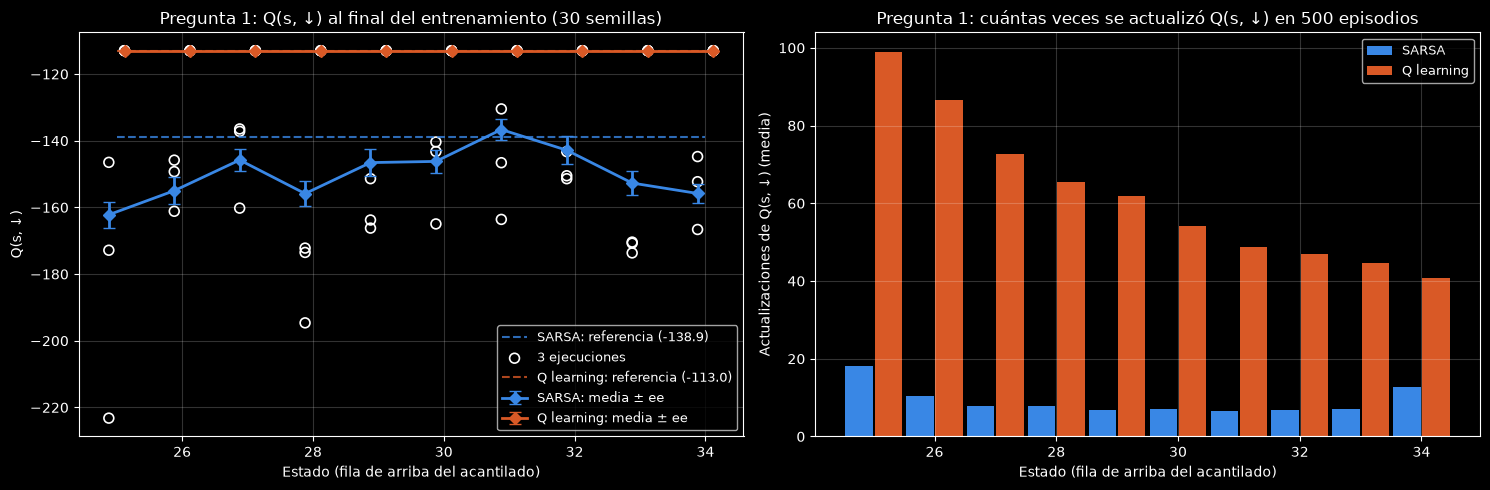

In [3]:
# Pregunta 1: imprima Q_sarsa y Q_qlearning (o las filas de estados 25 a 34) y
# compare el valor Q(s, 'abajo') entre ambas tablas
# Código original (celdas 2 a 7) como función de una corrida, con los episodios de
# SARSA y de Q learning intercalados como en el original. Con los valores por defecto
# reproduce el código original; EPSILON_DECAY, EPSILON_MIN y Q_INIT se usan en la pregunta 7.
def entrenar_cliff(semilla, NUM_EPISODES=500, ALPHA=0.5, GAMMA=1.0, EPSILON=0.3,
                   EPSILON_DECAY=1.0, EPSILON_MIN=0.0, Q_INIT=0.0):
    t0 = time.perf_counter()
    np.random.seed(semilla)
    env = gym.make('CliffWalking-v1')
    env.reset(seed=semilla)

    # Celda 3: inicialización de las tablas Q (el estado terminal vale 0)
    Q_sarsa = np.full((N_STATES, N_ACTIONS), Q_INIT)
    Q_qlearning = np.full((N_STATES, N_ACTIONS), Q_INIT)
    Q_sarsa[GOAL] = Q_qlearning[GOAL] = 0.0
    # Diagnósticos: visitas a cada (s, a), caídas y pasos por episodio, y la historia de
    # Q(s, abajo) en la fila 2, de sus actualizaciones y de Q(36, a)
    diag = {k: {'N': np.zeros((N_STATES, N_ACTIONS), dtype=int), 'caidas': [], 'pasos': [],
                'hist_abajo': [], 'hist_n_abajo': [], 'hist_inicio': []} for k in 'sq'}

    # Celda 4: política de comportamiento epsilon-greedy (común a ambos)
    def epsilon_greedy(Q, state, epsilon):
        if np.random.rand() < epsilon:
            return np.random.randint(N_ACTIONS)
        return int(np.argmax(Q[state]))

    # Celda 5: algoritmo SARSA (on-policy, Sutton & Barto)
    def run_sarsa_episode(Q, alpha, gamma, epsilon):
        d = diag['s']
        state, _ = env.reset()
        action = epsilon_greedy(Q, state, epsilon)
        total_reward, caidas, pasos = 0, 0, 0
        done = False
        while not done:
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            next_action = epsilon_greedy(Q, next_state, epsilon)

            # Actualización SARSA: usa la acción REALMENTE tomada en s' (on-policy)
            Q[state][action] += alpha * (
                reward + gamma * Q[next_state][next_action] - Q[state][action]
            )
            d['N'][state, action] += 1

            state, action = next_state, next_action
            total_reward += reward
            caidas += reward == -100
            pasos += 1
        d['caidas'].append(caidas)
        d['pasos'].append(pasos)
        return total_reward

    # Celda 6: algoritmo Q-Learning (off-policy, Sutton & Barto)
    def run_qlearning_episode(Q, alpha, gamma, epsilon):
        d = diag['q']
        state, _ = env.reset()
        total_reward, caidas, pasos = 0, 0, 0
        done = False
        while not done:
            action = epsilon_greedy(Q, state, epsilon)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Actualización Q-Learning: usa el máximo sobre s' (off-policy)
            best_next = np.max(Q[next_state])
            Q[state][action] += alpha * (
                reward + gamma * best_next - Q[state][action]
            )
            d['N'][state, action] += 1

            state = next_state
            total_reward += reward
            caidas += reward == -100
            pasos += 1
        d['caidas'].append(caidas)
        d['pasos'].append(pasos)
        return total_reward

    # Celda 7: entrenamiento de ambos agentes
    rewards_sarsa, rewards_qlearning = [], []
    prom100_sarsa, prom100_qlearning = [], []
    epsilon = EPSILON

    for ep in range(NUM_EPISODES):
        r_sarsa = run_sarsa_episode(Q_sarsa, ALPHA, GAMMA, epsilon)
        r_qlearning = run_qlearning_episode(Q_qlearning, ALPHA, GAMMA, epsilon)

        rewards_sarsa.append(r_sarsa)
        rewards_qlearning.append(r_qlearning)

        # Pregunta 3: registro de la recompensa promedio de los últimos 100 episodios
        # durante el entrenamiento, con la exploración incluida
        prom100_sarsa.append(np.mean(rewards_sarsa[-100:]))
        prom100_qlearning.append(np.mean(rewards_qlearning[-100:]))

        for k, Q in (('s', Q_sarsa), ('q', Q_qlearning)):
            diag[k]['hist_abajo'].append(Q[24:36, ABAJO].copy())
            diag[k]['hist_n_abajo'].append(diag[k]['N'][24:36, ABAJO].copy())
            diag[k]['hist_inicio'].append(Q[START].copy())

        # Pregunta 7: decaimiento opcional de ε (con EPSILON_DECAY = 1 queda constante)
        epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)

    return {'s': resultado_alg(env, Q_sarsa, rewards_sarsa, prom100_sarsa, diag['s']),
            'q': resultado_alg(env, Q_qlearning, rewards_qlearning, prom100_qlearning, diag['q']),
            'eps_final': epsilon, 'segundos': time.perf_counter() - t0}


res_base = ejecutar(entrenar_cliff, [{}])[0]  # configuración original, se reutiliza después
resumir(['original'], [res_base])

r1 = res_base[0]  # ejecución 1 (semilla 42): reproduce la celda original
print("Ejecución 1 (semilla 42), recompensa media de cada bloque de 50 episodios (igual que la celda original):")
for alg, k in ALGORITMOS:
    print(f"  {alg:<11}" + ''.join(f"{b:>8.1f}" for b in r1[k]['rewards'].reshape(10, 50).mean(axis=1)))
imprimir_tablas_q(r1, range(N_STATES), 'Q table completa al final del entrenamiento, ejecución 1 (semilla 42)')
for i in (1, 2):
    imprimir_tablas_q(res_base[i], BORDE, f'Estados 25 a 34, ejecución {i + 1} (semilla {SEMILLAS[i]})')

# Q(s, abajo) sobre el acantilado en todas las semillas
Qs = np.array([r['s']['Q'] for r in res_base])
Qq = np.array([r['q']['Q'] for r in res_base])
Ns = np.array([r['s']['N'] for r in res_base])
Nq = np.array([r['q']['N'] for r in res_base])
print("\nQ(s, ↓) sobre el acantilado: 3 ejecuciones, media de 30 semillas ± ee, referencia y "
      "cantidad media de actualizaciones de Q(s, ↓) (act.)")
cab = f"{'ejec 1':>8}{'ejec 2':>8}{'ejec 3':>8}{'media ± ee':>16}{'ref.':>8}{'act.':>7}"
print(f"{'':<7}|{'SARSA (ref.: mejor política ε greedy, ε = 0.3)':^55}|{'Q learning (ref.: Q*)':^55}")
print(f"{'estado':>6} |{cab}|{cab}")
for s in BORDE:
    fila = f"{s:>6} "
    for Qa, Na, ref in ((Qs, Ns, Q_REF[0.3]), (Qq, Nq, Q_OPT)):
        v = Qa[:, s, ABAJO]
        fila += ('|' + ''.join(f"{x:>8.1f}" for x in v[:N_EJECUCIONES]) + fmt_me(v, 16)
                 + f"{ref[s, ABAJO]:>8.1f}{Na[:, s, ABAJO].mean():>7.1f}")
    print(fila)

# Lo que suma cada actualización cuando ↓ lleva al acantilado (−100 y vuelta al inicio)
print("\nObjetivo de la actualización de Q(s, ↓) al caer, con las tablas finales (media de 30 semillas):")
print(f"  SARSA:      −100 + Q(36, A'), con A' elegida ε greedy: valor esperado "
      f"{-100 + valor_eps(Qs[:, START], 0.3).mean():.1f}; según la A' que salga va de "
      f"{-100 + Qs[:, START].min(axis=1).mean():.1f} a {-100 + Qs[:, START].max(axis=1).mean():.1f}")
print(f"  Q learning: −100 + max_a Q(36, a) = {-100 + Qq[:, START].max(axis=1).mean():.1f}")
print(f"  Q(36, a) medio: SARSA {np.round(Qs[:, START].mean(axis=0), 1)}, "
      f"Q learning {np.round(Qq[:, START].mean(axis=0), 1)}")

# Gráfico: Q(s, ↓) por estado y cantidad de actualizaciones
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
x = np.array(BORDE)
for (alg, k), Qa, Na, ref, d in zip(ALGORITMOS, (Qs, Qq), (Ns, Nq), (Q_REF[0.3], Q_OPT), (-0.12, 0.12)):
    v = Qa[:, BORDE, ABAJO]
    ax1.errorbar(x + d, v.mean(axis=0), yerr=v.std(axis=0, ddof=1) / np.sqrt(len(v)), fmt='D-',
                 color=COLOR_ALG[k], markersize=6, capsize=4, linewidth=2, label=f'{alg}: media ± ee')
    ax1.scatter(np.tile(x + d, N_EJECUCIONES), v[:N_EJECUCIONES].ravel(), s=50, facecolors='none',
                edgecolors='white', linewidths=1.2, label='3 ejecuciones' if k == 'q' else None)
    ax1.plot(x, ref[BORDE, ABAJO], '--', color=COLOR_ALG[k], alpha=0.8,
             label=f'{alg}: referencia ({ref[BORDE[0], ABAJO]:.1f})')
    ax2.bar(x + d * 2, Na[:, BORDE, ABAJO].mean(axis=0), width=0.45, color=COLOR_ALG[k], label=alg)
ax1.set_xlabel('Estado (fila de arriba del acantilado)'); ax1.set_ylabel('Q(s, ↓)')
ax1.set_title('Pregunta 1: Q(s, ↓) al final del entrenamiento (30 semillas)')
ax1.legend(fontsize=9); ax1.grid(alpha=0.2)
ax2.set_xlabel('Estado (fila de arriba del acantilado)'); ax2.set_ylabel('Actualizaciones de Q(s, ↓) (media)')
ax2.set_title('Pregunta 1: cuántas veces se actualizó Q(s, ↓) en 500 episodios')
ax2.legend(fontsize=9); ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Respuesta

Con la configuración original, Q(s, ↓) en los estados 25 a 34 vale exactamente −113.0 en la tabla de Q learning, en las 3 ejecuciones y en las 30 semillas. En la de SARSA vale entre −136.6 y −162.2 de media según el estado (con un error estándar de 3 a 4), y en las 3 ejecuciones va de −130.5 a −223.2.

La diferencia está en el término que cada algoritmo suma a la recompensa. Desde cualquiera de esos estados, ↓ da −100 y devuelve al agente al inicio (36), así que el objetivo de la actualización es −100 más el valor de lo que viene después, desde 36.

1. Q learning usa el máximo: −100 + max Q(36, ·). Ese máximo es Q(36, ↑) = −13, el valor del camino óptimo de 13 pasos suponiendo que de ahí en más actúa greedy. El objetivo es −113, igual a Q* calculado con el modelo. Como el entorno es determinista, una vez que Q(36, ·) convergió el objetivo es siempre el mismo y el valor queda fijo.
2. SARSA usa Q(36, A′), con A′ la acción que la política ε greedy elige realmente en 36. Ese término es más negativo por dos motivos. Primero, los valores de SARSA describen a la política que explora: Q(36, ↑) vale −45.4 de media, porque incluye las caídas y los rodeos que el 30% de acciones al azar va a provocar en el resto del episodio. Segundo, con probabilidad ε/4 = 0.075 la acción A′ es →, que vuelve a tirar al agente al acantilado (Q(36, →) = −160.7), y con probabilidad 0.15 es ↓ o ←, que chocan contra el borde de la grilla (−64.9 y −64.1). El valor esperado del objetivo es −156.8, y según la A′ que salga va de −145.3 a −260.7.

Además, SARSA actualiza esos pares pocas veces (entre 6.5 y 18 veces de media en 500 episodios, contra 41 a 99 en Q learning), porque su política se aleja del borde (va mas a lo "seguro"), y con α = 0.5 cada actualización mueve el valor hasta la mitad del objetivo, así que el valor final depende mucho de las últimas A′ que salieron. Por eso varía tanto entre semillas. Como referencia, el valor de la mejor política ε greedy con ε = 0.3, que es lo que SARSA estima cuando ε queda fijo, es −138.9; la media de SARSA queda algo por debajo porque su política real es peor que esa (Q(36, ↑) = −45.4 contra −29.0 en la referencia).

En resumen, Q learning valora caer como −100 seguido del mejor camino posible, y SARSA como −100 seguido de lo que realmente va a hacer explorando, que incluye la posibilidad de volver a caer.

Referencia: (Métodos de diferencia temporal, pág. 30) SARSA mira Q(S′, A′) y Q learning el máximo, (Métodos de diferencia temporal, págs. 15, 16 y 24 a 26) algoritmos SARSA y Q learning, (Métodos de diferencia temporal, pág. 36) −100 y vuelta al inicio en el acantilado y (Métodos de diferencia temporal, pág. 39) SARSA aprende incluyendo los pasos aleatorios de ε.

**2.** Modifique el código para que `EPSILON = 0` durante todo el entrenamiento (sin exploración: la política de comportamiento es 100% greedy desde el episodio 1).

¿Qué ocurre con las políticas finales de SARSA y de Q-Learning en este caso? ¿Convergen ahora a la misma política? ¿Por qué desaparece la diferencia entre ambos algoritmos cuando no hay exploración? (VALOR EJERCICIO 0.4)

30 corridas en 0 s con 32 procesos

configuración                   algoritmo     ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee   llega  pasos  entren. 100  caídas
original (EPSILON = 0.3)        SARSA         -200.0   -17.0   -19.0    -78.7   -120.8 ± 16.8   13/30   17.3        -62.9    0.25
original (EPSILON = 0.3)        Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0       -156.2    1.29
EPSILON = 0                     SARSA          -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0        -13.0    0.00
EPSILON = 0                     Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0        -13.0    0.00

Con EPSILON = 0 las 30 semillas dan exactamente las mismas tablas Q: True
Camino greedy de SARSA:      [36, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 47]
Camino greedy de Q learning: [36, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 47]
Estados con distinta acción greedy entre SARSA y Q learning: 14 de 

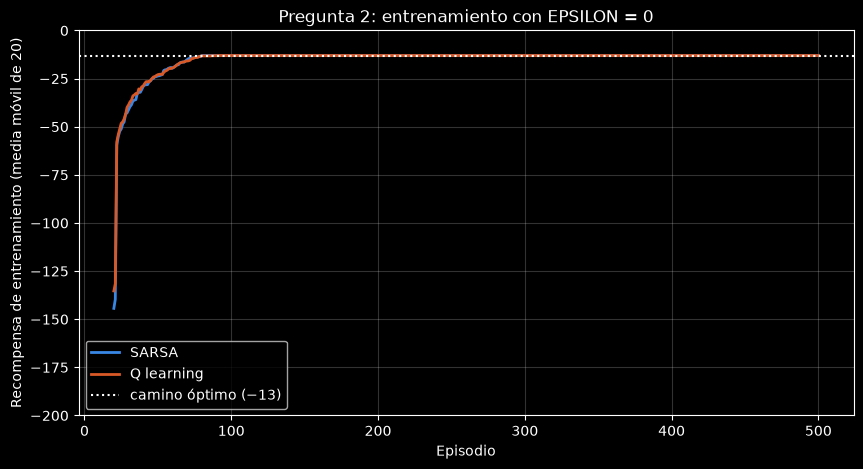

In [4]:
# Pregunta 2: modifique acá el código original fijando EPSILON = 0 durante todo
# el entrenamiento y vuelva a entrenar ambos agentes
# Se reutiliza entrenar_cliff de la pregunta 1; el cambio es EPSILON = 0.
res_p2 = ejecutar(entrenar_cliff, [dict(EPSILON=0.0)])[0]
resumir(['original (EPSILON = 0.3)', 'EPSILON = 0'], [res_base, res_p2])

r2 = res_p2[0]
iguales = all(np.array_equal(r[k]['Q'], r2[k]['Q']) for r in res_p2 for _, k in ALGORITMOS)
print(f"\nCon EPSILON = 0 las 30 semillas dan exactamente las mismas tablas Q: {iguales}")
print(f"Camino greedy de SARSA:      {r2['s']['camino']}")
print(f"Camino greedy de Q learning: {r2['q']['camino']}")
dif = [s for s in range(N_STATES) if s not in CLIFF and s != GOAL
       and np.argmax(r2['s']['Q'][s]) != np.argmax(r2['q']['Q'][s])]
print(f"Estados con distinta acción greedy entre SARSA y Q learning: {len(dif)} de 37, {dif}")
print(f"Tablas Q iguales entre SARSA y Q learning: {np.array_equal(r2['s']['Q'], r2['q']['Q'])} "
      f"(diferencia máxima {np.abs(r2['s']['Q'] - r2['q']['Q']).max():.1f})")
for alg, k in ALGORITMOS:
    print(f"{alg + ':':<12} recompensa de entrenamiento en los episodios 1 a 5 {r2[k]['rewards'][:5].astype(int)}, "
          f"media de los 500 episodios {r2[k]['rewards'].mean():.1f}, caídas en total {r2[k]['caidas'].sum()}")
imprimir_tablas_q(r2, list(range(24, 37)), 'Fila de arriba del acantilado e inicio con EPSILON = 0, ejecución 1')
mostrar_politicas(res_p2, 's', 'Política greedy de SARSA con EPSILON = 0')
mostrar_politicas(res_p2, 'q', 'Política greedy de Q learning con EPSILON = 0')

# Comprobación: con ε = 0 la acción siguiente de SARSA es argmax_a Q(s', a), la misma
# que usa Q learning. Solo queda una diferencia de orden: SARSA elige A' antes de
# actualizar Q(S, A), lo que importa cuando S' = S (un choque contra la pared).
def run_sarsa_episode_posterior(env, Q, alpha, gamma):
    """SARSA con ε = 0 que vuelve a elegir A' después de actualizar Q(S, A)."""
    state, _ = env.reset()
    action = int(np.argmax(Q[state]))
    done = False
    while not done:
        next_state, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        next_action = int(np.argmax(Q[next_state]))
        Q[state][action] += alpha * (reward + gamma * Q[next_state][next_action] - Q[state][action])
        next_action = int(np.argmax(Q[next_state]))  # cambio: elegir con Q ya actualizada
        state, action = next_state, next_action

env_p2 = gym.make('CliffWalking-v1')
Q_post = np.zeros((N_STATES, N_ACTIONS))
for ep in range(500):
    run_sarsa_episode_posterior(env_p2, Q_post, 0.5, 1.0)
print(f"\nSARSA con ε = 0 eligiendo A' después de actualizar da la misma tabla Q que Q learning: "
      f"{np.array_equal(Q_post, r2['q']['Q'])}")

# Gráfico: recompensa de entrenamiento con ε = 0 (igual en todas las semillas)
plt.figure(figsize=(10, 5))
for alg, k in ALGORITMOS:
    plt.plot(np.arange(20, 501), np.convolve(r2[k]['rewards'], np.ones(20) / 20, mode='valid'),
             color=COLOR_ALG[k], linewidth=2, label=alg)
plt.axhline(-13, color='white', linestyle=':', label='camino óptimo (−13)')
plt.ylim(-200, 0)
plt.xlabel('Episodio'); plt.ylabel('Recompensa de entrenamiento (media móvil de 20)')
plt.title('Pregunta 2: entrenamiento con EPSILON = 0')
plt.legend(); plt.grid(alpha=0.2)
plt.show()

Respuesta

Con EPSILON = 0 las dos políticas finales son la óptima: en las 30 semillas SARSA y Q learning llegan a la meta en 13 pasos por la fila 2, bordeando el acantilado, con recompensa −13. SARSA deja de aprender el camino largo. Las 30 semillas dan exactamente las mismas tablas, porque sin exploración no se usa ningún número al azar y CliffWalking es determinista.

¿Convergen a la misma política? Sobre el camino que usan, sí. Las tablas no son idénticas, por un detalle de orden: SARSA elige A′ antes de actualizar Q(S, A), y cuando S′ = S (un choque contra el borde de la grilla) esa actualización puede cambiar la mejor acción. La notebook comprueba que si SARSA elige A′ después de actualizar obtiene exactamente la misma tabla que Q learning.

Lo único que distingue a las dos actualizaciones es el valor del estado siguiente: SARSA usa Q(S′, A′) con la acción que va a tomar y Q learning usa max Q(S′, ·). Con ε = 0 la política de comportamiento es greedy, así que A′ = argmax Q(S′, ·) y las dos actualizaciones son la misma. La política que se ejecuta y la que se aprende coinciden, la distinción entre on policy y off policy deja de existir y SARSA ya no tiene exploración que tener en cuenta, así que no tiene motivo para alejarse del borde.

Sin ε, lo que hace explorar al principio es la inicialización: como todas las recompensas son negativas, Q = 0 es optimista y la política greedy prueba las acciones que siguen en 0. Por eso no se queda con el primer camino aceptable, como advierte la teoría para un agente puramente greedy. El costo es que cada acción mala se prueba muy pocas veces: Q(s, ↓) sobre el acantilado quedó cerca de −51, el valor de una sola actualización con α = 0.5, lejos de su valor real (−113), y no se corrige porque la política greedy no vuelve a elegirla.

Referencia: (Métodos de diferencia temporal, pág. 30) Q(S′, A′) frente al máximo, (Métodos de diferencia temporal, pág. 40) con ε cerca de 0, A′ es casi siempre la acción greedy y SARSA se parece a Q learning y (Métodos de diferencia temporal, pág. 41) agente puramente greedy.

**3.** Sin modificar el resto del código, agregue el registro de la recompensa acumulada promedio de los últimos 100 episodios **durante el entrenamiento** (no en la evaluación final greedy) para ambos algoritmos, usando `EPSILON = 0.3` constante.

¿Cuál de los dos algoritmos obtiene, en promedio, mejor recompensa mientras todavía se está entrenando (es decir, incluyendo las caídas al acantilado producto de la exploración)? Explique por qué SARSA puede tener mejor desempeño "en línea" durante el entrenamiento aunque termine aprendiendo una política final más larga y conservadora. (VALOR EJERCICIO 0.4)

Recompensa acumulada promedio de los últimos 100 episodios, registrada durante el entrenamiento (EPSILON = 0.3)
         |                 SARSA                  |               Q learning               
episodio |  ejec 1  ejec 2  ejec 3   media 30 ± ee|  ejec 1  ejec 2  ejec 3   media 30 ± ee
     100 |  -111.3  -115.2  -118.1    -131.8 ± 2.9|  -216.9  -210.4  -220.8    -200.1 ± 4.1
     200 |   -64.0   -82.4   -66.7     -67.5 ± 2.5|  -189.5  -188.0  -208.4    -182.4 ± 4.4
     300 |   -89.0   -49.6   -62.6     -63.9 ± 2.3|  -189.6  -190.7  -262.8    -191.4 ± 4.1
     400 |   -58.7   -56.5   -71.2     -59.5 ± 1.9|  -185.4  -149.5  -166.1    -178.8 ± 3.7
     500 |   -65.9   -92.2  -133.6     -62.9 ± 3.9|  -162.6  -160.2  -165.1    -156.2 ± 3.5

Durante el entrenamiento, media de 30 semillas ± ee:
  SARSA       recompensa media de los 500 episodios -77.1 ± 1.2, caídas por episodio (últimos 100) 0.25 ± 0.02, pasos por episodio (últimos 100) 38.2 ± 2.1
  Q learning  recompensa media de 

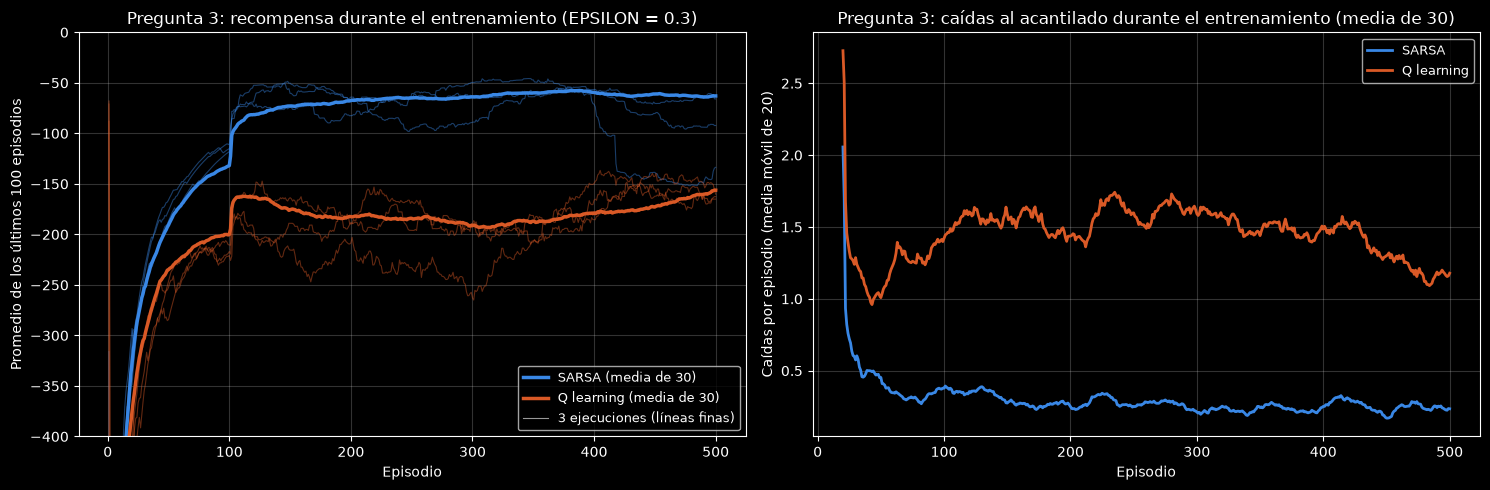

In [5]:
# Pregunta 3: agregue el registro de la recompensa acumulada promedio durante
# el entrenamiento (no en la evaluación greedy) para SARSA y Q-Learning
# El registro (prom100_sarsa y prom100_qlearning) está en el bucle de entrenamiento de
# entrenar_cliff, definido en la pregunta 1. Se reutilizan las corridas originales (ε = 0.3).
prom = {k: np.array([r[k]['prom100'] for r in res_base]) for _, k in ALGORITMOS}
print("Recompensa acumulada promedio de los últimos 100 episodios, registrada durante el entrenamiento (EPSILON = 0.3)")
cab = f"{'ejec 1':>8}{'ejec 2':>8}{'ejec 3':>8}{'media 30 ± ee':>16}"
print(f"{'':<9}|{'SARSA':^40}|{'Q learning':^40}")
print(f"{'episodio':>8} |{cab}|{cab}")
for ep in range(100, 501, 100):
    fila = f"{ep:>8} "
    for _, k in ALGORITMOS:
        v = prom[k][:, ep - 1]
        fila += '|' + ''.join(f"{x:>8.1f}" for x in v[:N_EJECUCIONES]) + fmt_me(v, 16)
    print(fila)

print("\nDurante el entrenamiento, media de 30 semillas ± ee:")
for alg, k in ALGORITMOS:
    rew = [r[k]['rewards'].mean() for r in res_base]
    cai = [r[k]['caidas'][-100:].mean() for r in res_base]
    pas = [r[k]['pasos_ep'][-100:].mean() for r in res_base]
    print(f"  {alg:<11} recompensa media de los 500 episodios {fmt_me(rew, 0)}, "
          f"caídas por episodio (últimos 100) {fmt_me(cai, 0, 2)}, pasos por episodio (últimos 100) {fmt_me(pas, 0)}")

print("\nValor del inicio que estima cada tabla para la política ε greedy que se ejecuta "
      "(media de 30 semillas), frente a lo que obtiene en los últimos 100 episodios:")
for alg, k in ALGORITMOS:
    v = [valor_eps(r[k]['Q'][START], 0.3) for r in res_base]
    print(f"  {alg:<11} estimado {fmt_me(v, 0)}   obtenido {fmt_me(prom[k][:, -1], 0)}")

print("\nPolítica greedy final (celda 9), para comparar:")
for alg, k in ALGORITMOS:
    llegan = [r for r in res_base if r[k]['llega']]
    print(f"  {alg:<11} llega a la meta en {len(llegan)} de {len(res_base)} semillas"
          + (f", en {np.mean([r[k]['pasos'] for r in llegan]):.1f} pasos de media" if llegan else ''))

# Gráfico: registro del promedio de 100 episodios y caídas por episodio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ep = np.arange(1, 501)
for alg, k in ALGORITMOS:
    for i in range(N_EJECUCIONES):
        ax1.plot(ep, prom[k][i], color=COLOR_ALG[k], linewidth=0.8, alpha=0.45)
    ax1.plot(ep, prom[k].mean(axis=0), color=COLOR_ALG[k], linewidth=2.5, label=f'{alg} (media de 30)')
    caidas = np.array([r[k]['caidas'] for r in res_base]).mean(axis=0)
    ax2.plot(np.arange(20, 501), np.convolve(caidas, np.ones(20) / 20, mode='valid'),
             color=COLOR_ALG[k], linewidth=2, label=alg)
ax1.plot([], [], color='white', linewidth=0.8, alpha=0.6, label='3 ejecuciones (líneas finas)')
ax1.set_ylim(-400, 0)
ax1.set_xlabel('Episodio'); ax1.set_ylabel('Promedio de los últimos 100 episodios')
ax1.set_title('Pregunta 3: recompensa durante el entrenamiento (EPSILON = 0.3)')
ax1.legend(fontsize=9); ax1.grid(alpha=0.2)
ax2.set_xlabel('Episodio'); ax2.set_ylabel('Caídas por episodio (media móvil de 20)')
ax2.set_title('Pregunta 3: caídas al acantilado durante el entrenamiento (media de 30)')
ax2.legend(fontsize=9); ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Respuesta

El registro muestra que SARSA obtiene mejor recompensa durante todo el entrenamiento. Media de 30 semillas del promedio de los últimos 100 episodios: en el episodio 100, −131.8 para SARSA y −200.1 para Q learning; en el 300, −63.9 y −191.4; en el 500, −62.9 ± 3.9 y −156.2 ± 3.5. 
En las 3 ejecuciones el valor final es −65.9, −92.2 y −133.6 para SARSA y −162.6, −160.2 y −165.1 para Q learning. Sobre los 500 episodios, la recompensa media por episodio es −77.1 ± 1.2 con SARSA y −181.8 ± 1.7 con Q learning. El salto de las dos curvas en el episodio 100 del gráfico es un efecto de la ventana: ahí empiezan a salir del promedio los primeros episodios, de recompensa muy negativa, como muestra el comienzo de las curvas.

La diferencia viene de las caídas: en los últimos 100 episodios Q learning cae al acantilado 1.29 veces por episodio y SARSA 0.25. Los episodios de Q learning son más cortos (28.4 pasos contra 38.2), pero cada caída cuesta −100.

Los dos se comportan con una política ε greedy con ε = 0.3, pero cada uno la arma sobre una tabla distinta.

1. Q learning aprende el valor de la política greedy, sin contar la exploración. Su política greedy bordea el acantilado por la fila 2, y como se comporta en forma ε greedy alrededor de ese camino, el 30% de acciones al azar lo tira al acantilado una y otra vez. Su tabla no lo refleja: para la política que ejecuta estima un valor del inicio de −20.6 (solo cuenta el azar de la primera acción) y en la práctica obtiene −156.2.
2. SARSA aprende el valor de la política que ejecuta, exploración incluida. Por eso las acciones que lo dejan junto al borde valen menos, y su política se aleja del acantilado hacia la fila 0, donde una acción al azar no lo hace caer. Su estimación del valor del inicio (−56.8 ± 1.8) está cerca de lo que obtiene (−62.9 ± 3.9).

El precio de SARSA es la política final. La política greedy de Q learning llega a la meta en las 30 semillas por el camino óptimo de 13 pasos, mientras que la de SARSA, cuando llega, tarda 17.3 pasos de media. Además, con estos hiperparámetros la política greedy de SARSA llega solo en 13 de 30 semillas y en las otras se queda en un bucle, un problema distinto que se analiza en la pregunta 7. SARSA optimiza lo que obtiene mientras sigue explorando y Q learning lo que obtendría si dejara de explorar: con exploración constante, el primero rinde más en línea y el segundo aprende la mejor política final.

Referencia: (Métodos de diferencia temporal, pág. 37) durante el aprendizaje Q learning acumula menos recompensa por las caídas, (Métodos de diferencia temporal, pág. 38) aprende el camino junto al borde y la exploración lo hace caer y (Métodos de diferencia temporal, pág. 39) SARSA toma un camino más seguro y su rendimiento en línea es mejor.

**4.** Imprima puntualmente los valores Q(36, a) para las 4 acciones posibles desde el estado inicial (36), en ambas tablas.

¿La acción con mayor valor Q en SARSA es la misma que en Q-Learning? ¿Cómo se relaciona esto con la primera decisión que toma cada agente al iniciar un episodio (alejarse de entrada del acantilado o intentar bordearlo)? (VALOR EJERCICIO 0.4)

In [6]:
# Pregunta 4: imprima puntualmente Q_sarsa[36] y Q_qlearning[36] y compare cuál
# es la acción con mayor valor Q en cada caso
# Se reutilizan las corridas originales (EPSILON = 0.3).
def tabla_estado(s, titulo):
    """Q(s, a) de las 3 ejecuciones, media de 30 semillas y referencias."""
    print(f"\n{titulo} (↑ 0, → 1, ↓ 2, ← 3)")
    print(f"{'':<34}" + ''.join(f"{ARROWS[a]:>9}" for a in range(N_ACTIONS)) + f"{'mejor':>7}")
    for i in range(N_EJECUCIONES):
        for alg, k in ALGORITMOS:
            q = res_base[i][k]['Q'][s]
            print(f"{f'ejec {i + 1}, {alg}':<34}" + ''.join(f"{v:>9.1f}" for v in q)
                  + f"{ARROWS[int(np.argmax(q))]:>7}")
    for alg, k in ALGORITMOS:
        Qa = np.array([r[k]['Q'][s] for r in res_base])
        m, ee = Qa.mean(axis=0), Qa.std(axis=0, ddof=1) / np.sqrt(len(Qa))
        print(f"{f'media 30, {alg}':<34}" + ''.join(f"{v:>9.1f}" for v in m) + f"{ARROWS[int(np.argmax(m))]:>7}")
        print(f"{'  ee':<34}" + ''.join(f"{v:>9.1f}" for v in ee))
    for nombre, Q in (('referencia Q*', Q_OPT), ('referencia mejor ε greedy, ε = 0.3', Q_REF[0.3])):
        print(f"{nombre:<34}" + ''.join(f"{v:>9.1f}" for v in Q[s]) + f"{ARROWS[int(np.argmax(Q[s]))]:>7}")
    for alg, k in ALGORITMOS:
        print(f"  acción de mayor valor en las 30 semillas, {alg}: "
              + contar_acciones(np.array([r[k]['Q'][s] for r in res_base])))


tabla_estado(START, 'Q(36, a) en el estado inicial')
tabla_estado(24, 'Q(24, a), el estado al que se llega con ↑ desde el inicio')

print("\nCamino greedy desde el inicio (primeros 20 estados) y fila por la que avanza:")
for i in range(N_EJECUCIONES):
    for alg, k in ALGORITMOS:
        r = res_base[i][k]
        texto = ' '.join(str(s) for s in r['camino'][:20]) + (' ...' if len(r['camino']) > 20 else '')
        estado = f"llega en {r['pasos']} pasos por la fila {fila_de_avance(r['camino'])}" if r['llega'] \
            else 'no llega a la meta'
        print(f"  ejec {i + 1}, {alg:<11} {estado:<34} {texto}")
print("\nFila por la que avanza el camino greedy en las 30 semillas (la fila 2 bordea el acantilado):")
for alg, k in ALGORITMOS:
    filas = [fila_de_avance(r[k]['camino']) if r[k]['llega'] else None for r in res_base]
    print(f"  {alg:<11} " + ', '.join(f"fila {f}: {filas.count(f)}" for f in (0, 1, 2) if filas.count(f))
          + (f", no llega: {filas.count(None)}" if filas.count(None) else ''))


Q(36, a) en el estado inicial (↑ 0, → 1, ↓ 2, ← 3)
                                          ↑        →        ↓        ←  mejor
ejec 1, SARSA                         -42.8   -148.5    -49.4    -48.2      ↑
ejec 1, Q learning                    -13.0   -113.0    -14.0    -14.0      ↑
ejec 2, SARSA                         -52.5   -178.3    -77.6    -64.8      ↑
ejec 2, Q learning                    -13.0   -113.0    -14.0    -14.0      ↑
ejec 3, SARSA                         -64.1   -168.4    -71.3    -95.2      ↑
ejec 3, Q learning                    -13.0   -113.0    -14.0    -14.0      ↑
media 30, SARSA                       -45.4   -160.7    -64.9    -64.1      ↑
  ee                                    1.8      2.7      3.4      3.1
media 30, Q learning                  -13.0   -113.0    -14.0    -14.0      ↑
  ee                                    0.0      0.0      0.0      0.0
referencia Q*                         -13.0   -113.0    -14.0    -14.0      ↑
referencia mejor ε greedy,

Respuesta

Q(36, a) en las 3 ejecuciones, en el orden ↑, →, ↓, ←: SARSA da −42.8, −148.5, −49.4 y −48.2 en la primera, −52.5, −178.3, −77.6 y −64.8 en la segunda y −64.1, −168.4, −71.3 y −95.2 en la tercera; Q learning da −13, −113, −14 y −14 en las tres. En la media de 30 semillas SARSA da −45.4, −160.7, −64.9 y −64.1, y Q learning −13.0, −113.0, −14.0 y −14.0, igual que Q*.

La acción de mayor valor es la misma, ↑, en las 3 ejecuciones de los dos algoritmos, en las 30 semillas de Q learning y en 28 de las 30 de SARSA. No puede ser de otra manera: desde el inicio, → cae al acantilado y ↓ y ← chocan contra el borde de la grilla y dejan al agente en el mismo lugar, así que ↑ es la única forma de salir. En las 2 semillas en que SARSA prefiere ↓ o ←, su política greedy se queda chocando en el inicio, un síntoma del ruido de sus valores con α = 0.5 que se analiza en la pregunta 7.

Lo que distingue a los agentes es la magnitud de los valores y la decisión siguiente.

1. Q(36, ↑) vale −13 en Q learning: el camino óptimo de 13 pasos, suponiendo que no vuelve a explorar. En SARSA vale −45.4 (la mejor política ε greedy con ε = 0.3 da −29.0), porque descuenta lo que le cuesta seguir explorando. Lo mismo pasa con Q(36, →): −113 contra −160.7.
2. La elección entre alejarse del acantilado y bordearlo se hace en el estado 24, al que se llega con ↑. Ahí Q learning prefiere → en las 30 semillas (Q(24, →) = −12 contra Q(24, ↑) = −14) y avanza por la fila 2, pegado al acantilado. SARSA prefiere ↑ en 28 de 30 (Q(24, ↑) = −40.9 contra Q(24, →) = −59.4 de media) y sigue subiendo hasta la fila 0. Los caminos greedy lo muestran: Q learning va por 36, 24, 25, ..., 35, 47 en las 30 semillas, y SARSA, en las 13 semillas en que llega, avanza por la fila 0 (en 17 pasos en la ejecución 2 y en 19 en la 3).

La primera acción es la misma, pero para SARSA ↑ es el comienzo de un camino que se aleja del acantilado hasta la fila de arriba, y su valor ya incluye esa decisión; para Q learning es el primer paso del camino que lo bordea.

Referencia: (Métodos de diferencia temporal, pág. 36) dinámica del acantilado, (Métodos de diferencia temporal, págs. 38 y 39) Q learning aprende el camino junto al borde y SARSA un camino más seguro y (Métodos de diferencia temporal, pág. 42) SARSA aprende sobre lo que hace y Q learning sobre lo que es mejor.

**5.** Durante los primeros episodios de entrenamiento, con `EPSILON` alto, ambos agentes caen muchas veces al acantilado. Inspeccione cómo cambia con las corridas el valor Q(s, "abajo") de un estado cercano al acantilado en `Q_qlearning` a medida que aumenta la cantidad de episodios (imprímalo, por ejemplo, cada 100 episodios).

¿Ese valor queda "marcado" para siempre por las malas experiencias iniciales, o el algoritmo logra corregirlo a medida que seguimos actualizando Q? Justifique la respuesta observando la ecuación de actualización de Q-Learning. (VALOR EJERCICIO 0.4)

Q learning: Q(30, ↓) al final de cada episodio (EPSILON = 0.3, ALPHA = 0.5); referencia Q*(30, ↓) = -113.0
episodio   ejec 1   ejec 2   ejec 3    media 30 ± ee  −100 + max Q(36)  act. de Q(s, ↓)  caídas acum.
       1      0.0      0.0      0.0      -15.0 ± 4.8            -101.2              0.3           5.3
       2    -77.6    -51.5      0.0      -66.8 ± 4.4            -104.6              1.8          23.2
       5    -91.5    -51.5    -90.7      -79.8 ± 3.0            -106.2              2.4          32.8
      10    -99.6    -93.0    -98.9      -88.2 ± 2.8            -107.7              3.1          40.2
      20   -107.5   -100.8   -103.6      -95.3 ± 2.0            -110.0              3.8          54.5
      50   -112.1   -106.8   -109.9     -107.7 ± 0.9            -113.0              6.1          86.1
     100   -113.0   -113.0   -112.8     -112.6 ± 0.2            -113.0             10.7         154.1
     200   -113.0   -113.0   -113.0     -113.0 ± 0.0            -113.0       

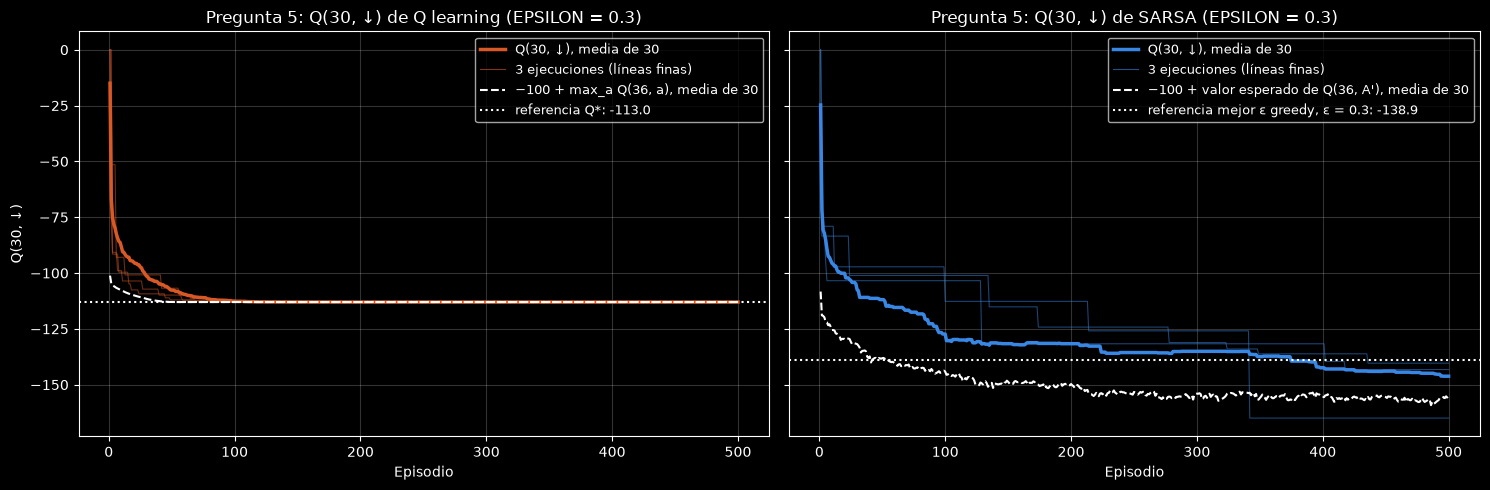

In [7]:
# Pregunta 5: imprima cómo evoluciona Q_qlearning[s]['abajo'] para un estado
# cercano al acantilado cada 100 episodios de entrenamiento
# Se reutilizan las corridas originales (EPSILON = 0.3). entrenar_cliff guarda en cada
# episodio Q(s, abajo) de la fila 2, cuántas veces se actualizó y Q(36, a).
S_P5 = 30  # estado del medio de la fila de arriba del acantilado
j = S_P5 - 24
hist = {k: np.array([r[k]['hist_abajo'][:, j] for r in res_base]) for _, k in ALGORITMOS}
inicio = {k: np.array([r[k]['hist_inicio'] for r in res_base]) for _, k in ALGORITMOS}  # (30, 500, 4)
n_act = np.array([r['q']['hist_n_abajo'][:, j] for r in res_base])
caidas_acum = np.array([np.cumsum(r['q']['caidas']) for r in res_base])
hq, max_inicio = hist['q'], inicio['q'].max(axis=2)

print(f"Q learning: Q({S_P5}, ↓) al final de cada episodio (EPSILON = 0.3, ALPHA = 0.5); "
      f"referencia Q*({S_P5}, ↓) = {Q_OPT[S_P5, ABAJO]:.1f}")
print(f"{'episodio':>8}{'ejec 1':>9}{'ejec 2':>9}{'ejec 3':>9}{'media 30 ± ee':>17}"
      f"{'−100 + max Q(36)':>18}{'act. de Q(s, ↓)':>17}{'caídas acum.':>14}")
for ep in [1, 2, 5, 10, 20, 50, 100, 200, 300, 400, 500]:
    v = hq[:, ep - 1]
    print(f"{ep:>8}" + ''.join(f"{x:>9.1f}" for x in v[:N_EJECUCIONES]) + fmt_me(v, 17)
          + f"{-100 + max_inicio[:, ep - 1].mean():>18.1f}{n_act[:, ep - 1].mean():>17.1f}"
          + f"{caidas_acum[:, ep - 1].mean():>14.1f}")
print(f"\nMínimo de Q({S_P5}, ↓) de Q learning en los 500 episodios y las 30 semillas: {hq.min():.1f}")
print(f"Mínimo de max_a Q(36, a) de Q learning en los 500 episodios y las 30 semillas: {max_inicio.min():.1f}")
print(f"Diferencia máxima entre Q({S_P5}, ↓) y −113 desde el episodio 200: {np.abs(hq[:, 199:] + 113).max():.3f}")

print("\nQ learning, Q(s, ↓) de los estados 25 a 34, media de 30 semillas:")
print(f"{'episodio':>8}" + ''.join(f"{s:>8}" for s in BORDE))
for ep in [10, 50, 100, 200, 300, 400, 500]:
    print(f"{ep:>8}" + ''.join(f"{np.mean([r['q']['hist_abajo'][ep - 1, s - 24] for r in res_base]):>8.1f}"
                               for s in BORDE))

# Gráfico: Q(30, ↓) por episodio en Q learning y, para comparar, en SARSA
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
ep = np.arange(1, 501)
paneles = (('Q learning', 'q', Q_OPT, 'Q*', inicio['q'].max(axis=2), '−100 + max_a Q(36, a)'),
           ('SARSA', 's', Q_REF[0.3], 'mejor ε greedy, ε = 0.3', valor_eps(inicio['s'], 0.3),
            "−100 + valor esperado de Q(36, A')"))
for ax, (alg, k, ref, nombre_ref, objetivo, nombre_obj) in zip(axes, paneles):
    for i in range(N_EJECUCIONES):
        ax.plot(ep, hist[k][i], color=COLOR_ALG[k], linewidth=0.8, alpha=0.5)
    ax.plot(ep, hist[k].mean(axis=0), color=COLOR_ALG[k], linewidth=2.5, label=f'Q({S_P5}, ↓), media de 30')
    ax.plot([], [], color=COLOR_ALG[k], linewidth=0.8, alpha=0.6, label='3 ejecuciones (líneas finas)')
    ax.plot(ep, -100 + objetivo.mean(axis=0), color='white', linestyle='--', linewidth=1.5,
            label=f'{nombre_obj}, media de 30')
    ax.axhline(ref[S_P5, ABAJO], color='white', linestyle=':', linewidth=1.5,
               label=f'referencia {nombre_ref}: {ref[S_P5, ABAJO]:.1f}')
    ax.set_xlabel('Episodio'); ax.set_title(f'Pregunta 5: Q({S_P5}, ↓) de {alg} (EPSILON = 0.3)')
    ax.legend(fontsize=9, loc='upper right'); ax.grid(alpha=0.2)
axes[0].set_ylabel(f'Q({S_P5}, ↓)')
plt.tight_layout()
plt.show()

Respuesta

Se siguió Q(30, ↓) de Q learning, en el medio de la fila de arriba del acantilado, con la configuración original. Media de 30 semillas al final de los episodios 1, 2, 10, 50, 100 y 200: −15.0, −66.8, −88.2, −107.7, −112.6 y −113.0. Desde el episodio 200 hasta el 500 queda en −113.0 en todas las semillas (la mayor diferencia con −113 es 0.003). Las 3 ejecuciones hacen el mismo recorrido: −77.6, −51.5 y 0.0 en el episodio 2, −112.1, −106.8 y −109.9 en el 50, y −113.0 en las tres desde el 200. Los demás estados de la fila (25 a 34) también llegan a −113.0 en el episodio 200. Ese valor es exactamente Q*(30, ↓) = −100 + V*(36) = −100 − 13.

No queda marcado por las malas experiencias iniciales. En los primeros 100 episodios Q learning cae al acantilado 154 veces de media, y aun así Q(30, ↓) no baja de −113 en ningún momento ni en ninguna semilla (el mínimo de todo el entrenamiento es −113.0): arranca en 0 y baja hasta su valor real, sin pasarse.

La ecuación de actualización lo explica: Q(30, ↓) ← Q(30, ↓) + α [−100 + max Q(36, ·) − Q(30, ↓)].

1. El objetivo no depende de lo que el agente hizo después de caer. La recompensa de caer es siempre −100, porque el entorno es determinista, y lo que sigue se valora con max Q(36, ·), el mejor camino desde el inicio según la tabla, no con los rodeos y las caídas que efectivamente ocurrieron. Al principio ese máximo todavía es optimista (−1.2 al final del episodio 1, porque Q empieza en 0) y baja hasta −13.0 hacia el episodio 50, cuando el objetivo llega a −113. Como Q arranca en 0, por encima de cualquier valor real, y el entorno es determinista, el objetivo nunca queda por debajo del valor real, y por eso no hay nada que corregir hacia arriba.
2. Con α constante, cada actualización reemplaza una fracción α del valor viejo por el objetivo nuevo. Después de n actualizaciones lo que queda del valor inicial pesa (1 − α)ⁿ = 0.5ⁿ, menos del 0.1% después de 10. Nada de lo aprendido al principio sobrevive si el par se sigue actualizando.
3. Para eso hace falta seguir visitando el par. Con ε = 0.3, cada vez que el agente pasa por 30 elige ↓ con probabilidad 0.075, y Q(30, ↓) se actualizó 10.7 veces de media en los primeros 100 episodios y 54.2 en los 500. En la pregunta 2, con ε = 0, ese mismo valor quedó en −51.4 después de una sola actualización y no se corrigió nunca, porque la política greedy no volvió a elegir ↓.

En SARSA, en cambio, el valor queda atado a la exploración mientras ε no baje: su objetivo usa Q(36, A′) con la acción que se toma, y Q(30, ↓) termina en −146.2 de media, más cerca de la referencia de la mejor política ε greedy (−138.9) que de −113, como muestra el panel derecho del gráfico.

Referencia: (Métodos de diferencia temporal, págs. 24 a 26 y 30) actualización de Q learning con el máximo del estado siguiente, (Métodos de diferencia temporal, pág. 7) α como peso de la experiencia más reciente y (Métodos de diferencia temporal, págs. 9 y 10) error TD.

**6.** Modifique la función `evaluate_policy` para que, en lugar de actuar 100% greedy, la evaluación final se haga con una política ε-greedy residual (por ejemplo `epsilon=0.05`), igual que hace la política de comportamiento durante el entrenamiento.

¿Qué le pasa a la recompensa obtenida por la política de Q-Learning frente a la de SARSA cuando queda algo de exploración residual en la evaluación? ¿Por qué SARSA resulta más robusto ante este tipo de evaluación que Q-Learning? (VALOR EJERCICIO 0.4)

30 corridas evaluadas en 7 s con 32 procesos

Evaluación con ε residual = 0.05 de las políticas del entrenamiento original (1000 episodios por semilla; caídas y llega son por episodio)
algoritmo   semillas              ejec 1  ejec 2  ejec 3      media ± ee   greedy   cambio  caídas   llega
SARSA       todas (30)            -190.6   -19.1   -21.0    -95.6 ± 14.1   -120.8    +25.2   0.078   0.742
Q learning  todas (30)             -30.1   -29.3   -29.2     -29.5 ± 0.3    -13.0    -16.5   0.149   1.000
SARSA       SARSA llega (13)                                 -20.0 ± 0.3    -17.3     -2.7   0.016   1.000
Q learning  SARSA llega (13)                                 -29.3 ± 0.4    -13.0    -16.3   0.147   1.000
Mejor recompensa esperada posible con ε = 0.05 (referencia): -17.5

                 todas las semillas         semillas en que SARSA greedy llega (13)   
ε residual           SARSA      Q learning           SARSA      Q learning  caídas S  caídas Q  mejor posible
       0.0   -1

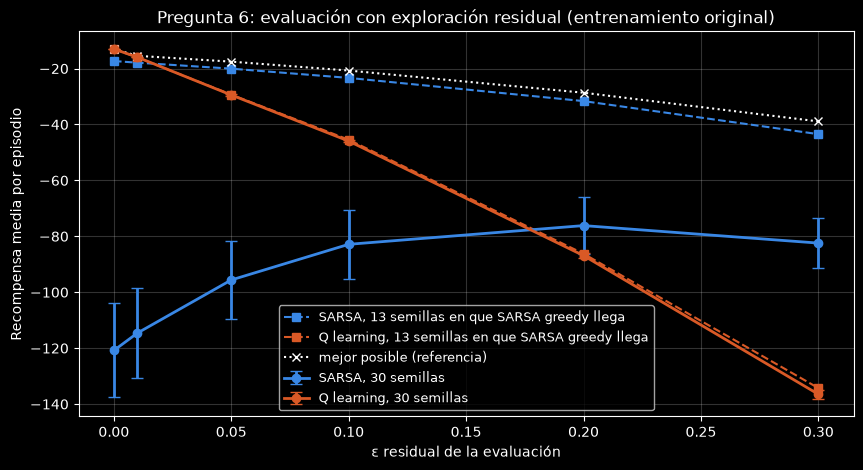

In [8]:
# Pregunta 6: modifique evaluate_policy para que use una política epsilon-greedy
# residual (por ejemplo epsilon=0.05) en lugar de 100% greedy
# evaluate_policy de la celda 9 con una política ε greedy residual en lugar de 100% greedy.
# Con ε > 0 el resultado es aleatorio: se promedian n_eval episodios con semilla fija.
def evaluate_policy_eps(Q, epsilon=0.05, n_eval=1000, max_steps=200, semilla=0):
    np.random.seed(semilla)
    env = gym.make('CliffWalking-v1')
    n = n_eval if epsilon > 0 else 1  # con ε = 0 es la evaluación greedy original
    total, caidas, llegadas = 0, 0, 0
    for _ in range(n):
        state, _ = env.reset()
        done = False
        steps = 0
        while not done and steps < max_steps:
            if np.random.rand() < epsilon:  # cambio: exploración residual
                action = np.random.randint(N_ACTIONS)
            else:
                action = int(np.argmax(Q[state]))
            state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            total += reward
            caidas += reward == -100
            llegadas += terminated
            steps += 1
    return total / n, caidas / n, llegadas / n


EPS_EVAL = [0.0, 0.01, 0.05, 0.1, 0.2, 0.3]
# Mejor recompensa esperada posible para cada ε residual: valor del inicio de la mejor
# política ε greedy (calculado con el modelo, solo como referencia)
MEJOR_POSIBLE = [Q_OPT[START].max()] + [valor_eps(q_referencia(e)[START], e) for e in EPS_EVAL[1:]]


def evaluar_corrida(Q_sarsa, Q_qlearning, semilla):
    """Las dos tablas de una corrida con cada ε residual: recompensa, caídas y llegadas por episodio."""
    return {k: np.array([evaluate_policy_eps(Q, e, semilla=semilla) for e in EPS_EVAL])
            for k, Q in (('s', Q_sarsa), ('q', Q_qlearning))}


def evaluar_eps(res):
    """Evalúa en paralelo las tablas Q finales de todas las semillas."""
    t0 = time.perf_counter()
    ev = Parallel(n_jobs=N_PROCESOS)(delayed(evaluar_corrida)(r['s']['Q'], r['q']['Q'], s)
                                     for r, s in zip(res, SEMILLAS))
    print(f"{len(res)} corridas evaluadas en {time.perf_counter() - t0:.0f} s con {N_PROCESOS} procesos\n")
    return {k: np.array([e[k] for e in ev]) for _, k in ALGORITMOS}  # (semilla, ε, medida)


def tabla_eps(ev, res, titulo, e=0.05):
    """Recompensa con ε residual frente a la greedy, en todas las semillas y en las semillas
    cuya política greedy de SARSA llega a la meta."""
    ie = EPS_EVAL.index(e)
    llega = np.array([r['s']['llega'] for r in res])
    print(f"{titulo} (1000 episodios por semilla; caídas y llega son por episodio)")
    print(f"{'algoritmo':<12}{'semillas':<20}{'ejec 1':>8}{'ejec 2':>8}{'ejec 3':>8}{'media ± ee':>16}"
          f"{'greedy':>9}{'cambio':>9}{'caídas':>8}{'llega':>8}")
    grupos = [(f'todas ({len(res)})', np.ones(len(res), dtype=bool))]
    if 1 < llega.sum() < len(res):
        grupos.append((f'SARSA llega ({llega.sum()})', llega))
    for nombre, m in grupos:
        for alg, k in ALGORITMOS:
            v, g = ev[k][m, ie, 0], ev[k][m, 0, 0]
            tres = ''.join(f"{x:>8.1f}" for x in ev[k][:N_EJECUCIONES, ie, 0]) if m.all() else ' ' * 24
            print(f"{alg:<12}{nombre:<20}{tres}{fmt_me(v, 16)}{g.mean():>9.1f}{v.mean() - g.mean():>+9.1f}"
                  f"{ev[k][m, ie, 1].mean():>8.3f}{ev[k][m, ie, 2].mean():>8.3f}")
    print(f"Mejor recompensa esperada posible con ε = {e} (referencia): {MEJOR_POSIBLE[ie]:.1f}")


def tabla_barrido(ev, res):
    """Recompensa media según el ε residual de la evaluación."""
    llega = np.array([r['s']['llega'] for r in res])
    print(f"\n{'':<10}{'todas las semillas':^32}{f'semillas en que SARSA greedy llega ({llega.sum()})':^44}")
    print(f"{'ε residual':>10}{'SARSA':>16}{'Q learning':>16}{'SARSA':>16}{'Q learning':>16}"
          f"{'caídas S':>10}{'caídas Q':>10}{'mejor posible':>15}")
    for ie, e in enumerate(EPS_EVAL):
        print(f"{e:>10}{fmt_me(ev['s'][:, ie, 0], 16)}{fmt_me(ev['q'][:, ie, 0], 16)}"
              f"{fmt_me(ev['s'][llega, ie, 0], 16)}{fmt_me(ev['q'][llega, ie, 0], 16)}"
              f"{ev['s'][llega, ie, 1].mean():>10.3f}{ev['q'][llega, ie, 1].mean():>10.3f}{MEJOR_POSIBLE[ie]:>15.1f}")


def graficar_eps(ev, res, titulo):
    """Recompensa media ± ee según el ε residual de la evaluación."""
    llega = np.array([r['s']['llega'] for r in res])
    plt.figure(figsize=(10, 5))
    for alg, k in ALGORITMOS:
        v = ev[k][:, :, 0]
        plt.errorbar(EPS_EVAL, v.mean(axis=0), yerr=v.std(axis=0, ddof=1) / np.sqrt(len(res)),
                     color=COLOR_ALG[k], marker='o', linewidth=2, capsize=4, label=f'{alg}, {len(res)} semillas')
        if 1 < llega.sum() < len(res):
            plt.plot(EPS_EVAL, v[llega].mean(axis=0), color=COLOR_ALG[k], linestyle='--', marker='s',
                     label=f'{alg}, {llega.sum()} semillas en que SARSA greedy llega')
    plt.plot(EPS_EVAL, MEJOR_POSIBLE, color='white', linestyle=':', marker='x', label='mejor posible (referencia)')
    plt.xlabel('ε residual de la evaluación'); plt.ylabel('Recompensa media por episodio')
    plt.title(titulo); plt.legend(fontsize=9); plt.grid(alpha=0.2)
    plt.show()


# Se evalúan las tablas Q finales de las corridas originales (EPSILON = 0.3 al entrenar)
ev_base = evaluar_eps(res_base)
tabla_eps(ev_base, res_base, 'Evaluación con ε residual = 0.05 de las políticas del entrenamiento original')
tabla_barrido(ev_base, res_base)
graficar_eps(ev_base, res_base, 'Pregunta 6: evaluación con exploración residual (entrenamiento original)')

Respuesta

Se reescribió evaluate_policy como evaluate_policy_eps, que elige una acción al azar con probabilidad ε y la greedy en el resto de los pasos (con ε = 0 es la evaluación original), y se evaluaron las tablas finales del entrenamiento original en 1000 episodios por semilla.

Con ε = 0.05 la recompensa de Q learning cae de −13.0 a −29.5, con 0.149 caídas al acantilado por episodio. SARSA, en las 13 de 30 semillas en que su política greedy llega a la meta, pasa de −17.3 a −20.0, cerca de lo mejor posible con ε = 0.05 (−17.5): pierde 2.7 contra 16.3 de Q learning en esas mismas semillas. En las otras 17 su política se queda en un bucle y la media de las 30 semillas da peor (−95.6), pero con las tablas de la pregunta 7, en las que SARSA siempre llega, el resultado se repite: −18.2 para SARSA y −30.5 para Q learning. La brecha crece con ε: con ε = 0.3 Q learning obtiene −134.3 y SARSA −43.5.

Por qué SARSA es más robusto. El camino de Q learning pasa por 11 estados desde los que una sola acción al azar lo tira al acantilado. Con ε = 0.05 esa acción sale con probabilidad 0.05/4 = 0.0125 en cada uno, y eso da unas 0.15 caídas de −100 por episodio, lo que se mide. Q learning es off policy: aprendió el valor de la política greedy y su tabla no tiene en cuenta que el agente puede seguir explorando. SARSA es on policy: sus valores ya incluyen la exploración, así que su política evita los estados donde un error cuesta −100 y avanza lejos del borde, donde una acción al azar solo agrega pasos.

Referencia: (Métodos de diferencia temporal, pág. 39) SARSA aprende una política más segura dado que va a seguir explorando, (Métodos de diferencia temporal, pág. 42) on policy y off policy en el acantilado y (Métodos de Monte Carlo, págs. 83 y 84) probabilidades de la política ε greedy.

**7.** Ajuste los hiperparámetros que considere necesarios (inicialización de Q, `ALPHA`, `EPSILON` y/o un esquema de decaimiento, `NUM_EPISODES`) hasta lograr que **ambos** algoritmos aprendan una política razonable. Imprima entonces la Q-table completa de ambos y, para cada estado de la fila adyacente al acantilado, identifique cuál es la acción con mayor valor Q en cada tabla.

Con esa evidencia concreta (los valores de la Q-table, no solo el dibujo de la política), explique en sus propias palabras por qué SARSA, al ser **on-policy**, "sabe" que va a seguir explorando ocasionalmente y por eso penaliza más los estados cercanos al precipicio, mientras que Q-Learning, al ser **off-policy**, asume que de ahora en más actuará siempre de forma greedy y por eso no penaliza esos estados de la misma manera. (VALOR EJERCICIO 0.9)

180 corridas en 8 s con 32 procesos

configuración                   algoritmo     ejec 1  ejec 2  ejec 3  media 3   media 30 ± ee   llega  pasos  entren. 100  caídas
original (α 0.5, ε 0.3, N 500)  SARSA         -200.0   -17.0   -19.0    -78.7   -120.8 ± 16.8   13/30   17.3        -62.9    0.25
original (α 0.5, ε 0.3, N 500)  Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0       -156.2    1.29
α 0.5, ε 0.3, N 2000            SARSA         -200.0   -17.0  -200.0   -139.0   -126.8 ± 16.6   12/30   17.0        -63.2    0.24
α 0.5, ε 0.3, N 2000            Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0       -126.7    1.02
α 0.1, ε 0.3, N 2000            SARSA          -17.0   -17.0   -17.0    -17.0     -17.0 ± 0.0   30/30   17.0        -41.2    0.16
α 0.1, ε 0.3, N 2000            Q learning     -13.0   -13.0   -13.0    -13.0     -13.0 ± 0.0   30/30   13.0       -183.0    1.53
α 0.5, ε 0.1, N 2000            SARSA          -17.0 

30 corridas evaluadas en 2 s con 32 procesos

Evaluación con ε residual = 0.05 de la configuración elegida (1000 episodios por semilla; caídas y llega son por episodio)
algoritmo   semillas              ejec 1  ejec 2  ejec 3      media ± ee   greedy   cambio  caídas   llega
SARSA       todas (30)             -17.7   -20.7   -19.3     -18.2 ± 0.2    -15.4     -2.8   0.018   1.000
Q learning  todas (30)             -32.0   -29.8   -29.9     -30.5 ± 0.3    -13.0    -17.5   0.156   1.000
Mejor recompensa esperada posible con ε = 0.05 (referencia): -17.5

                 todas las semillas         semillas en que SARSA greedy llega (30)   
ε residual           SARSA      Q learning           SARSA      Q learning  caídas S  caídas Q  mejor posible
       0.0     -15.4 ± 0.1     -13.0 ± 0.0     -15.4 ± 0.1     -13.0 ± 0.0     0.000     0.000          -13.0
      0.01     -15.9 ± 0.2     -16.1 ± 0.1     -15.9 ± 0.2     -16.1 ± 0.1     0.003     0.027          -15.4
      0.05     -18.2 ± 0.

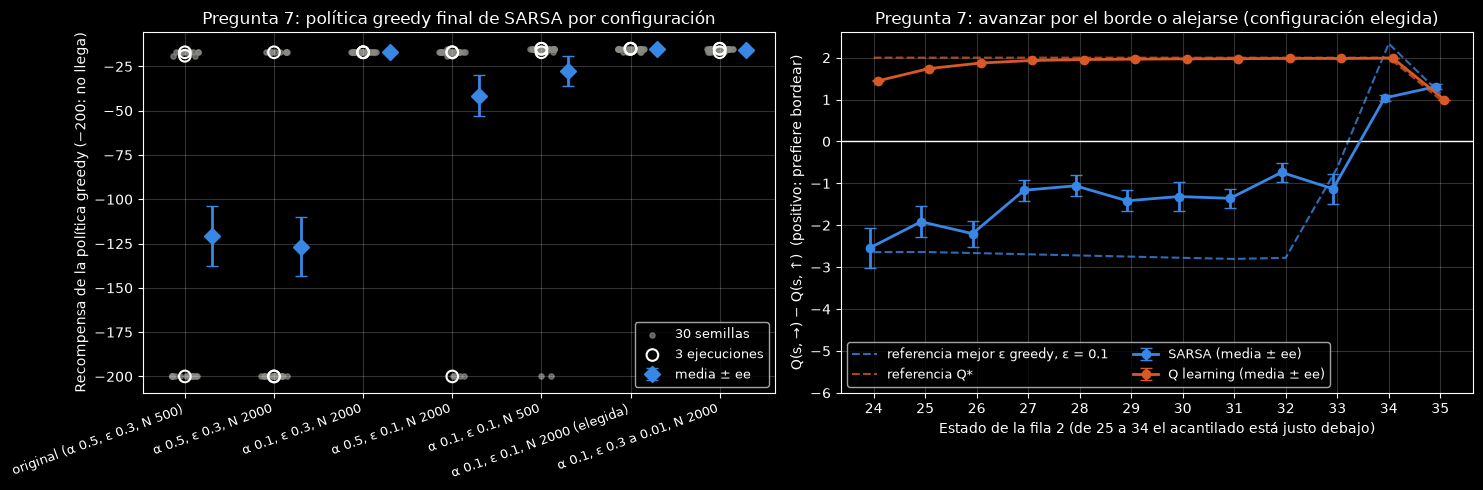

In [9]:
# Pregunta 7: ajuste los hiperparámetros necesarios, entrene ambos agentes,
# imprima las Q-tables completas y compare la acción de mayor valor en los
# estados junto al acantilado
# Se reutiliza entrenar_cliff; cambian ALPHA, EPSILON (fijo o con decaimiento) y NUM_EPISODES.
# Q se sigue inicializando en 0, que ya es optimista porque todas las recompensas son negativas.
def decay_a_mitad(n, eps_start=0.3, eps_end=0.01):
    """EPSILON_DECAY para que ε pase de eps_start a eps_end a la mitad del entrenamiento."""
    return (eps_end / eps_start) ** (1 / (0.5 * n))


ELEGIDA = 'α 0.1, ε 0.1, N 2000 (elegida)'
CONFIGS_P7 = {
    'α 0.5, ε 0.3, N 2000': dict(NUM_EPISODES=2000),
    'α 0.1, ε 0.3, N 2000': dict(ALPHA=0.1, NUM_EPISODES=2000),
    'α 0.5, ε 0.1, N 2000': dict(EPSILON=0.1, NUM_EPISODES=2000),
    'α 0.1, ε 0.1, N 500': dict(ALPHA=0.1, EPSILON=0.1),
    ELEGIDA: dict(ALPHA=0.1, EPSILON=0.1, NUM_EPISODES=2000),
    'α 0.1, ε 0.3 a 0.01, N 2000': dict(ALPHA=0.1, NUM_EPISODES=2000,
                                        EPSILON_DECAY=decay_a_mitad(2000), EPSILON_MIN=0.01),
}
etiquetas_p7 = ['original (α 0.5, ε 0.3, N 500)'] + list(CONFIGS_P7)
res_p7 = [res_base] + ejecutar(entrenar_cliff, list(CONFIGS_P7.values()))
resumir(etiquetas_p7, res_p7)

print("\nSARSA en las filas 0 y 1 frente a la mejor política ε greedy para su ε final: error medio de Q,"
      "\nporcentaje de estados con la misma acción greedy y brecha media entre la mejor y la segunda acción")
print(f"{'configuración':<32}{'ε final':>8}{'error medio de Q':>18}{'misma acción':>14}{'brecha':>8}")
for et, res in zip(etiquetas_p7, res_p7):
    e = res[0]['eps_final']
    ref = Q_REF[min(Q_REF, key=lambda x: abs(x - e))][:24]
    Qs = np.array([r['s']['Q'][:24] for r in res])
    orden = np.sort(ref, axis=1)
    print(f"{et:<32}{e:>8.2f}{np.abs(Qs - ref).mean():>18.2f}"
          f"{100 * (Qs.argmax(axis=2) == ref.argmax(axis=1)).mean():>13.0f}%{(orden[:, -1] - orden[:, -2]).mean():>8.2f}")

# Configuración elegida: Q table completa y fila adyacente al acantilado
res_el = res_p7[etiquetas_p7.index(ELEGIDA)]
EPS_EL = 0.1
imprimir_tablas_q(res_el[0], range(N_STATES), 'Q table completa con la configuración elegida, ejecución 1 (semilla 42)')
for i in (1, 2):
    imprimir_tablas_q(res_el[i], range(24, 36),
                      f'Fila 2 con la configuración elegida, ejecución {i + 1} (semilla {SEMILLAS[i]})')

FILA2 = list(range(24, 36))
Q7 = {k: np.array([r[k]['Q'] for r in res_el]) for _, k in ALGORITMOS}
N7 = {k: np.array([r[k]['N'] for r in res_el]) for _, k in ALGORITMOS}
print("\nFila adyacente al acantilado (estados 24 a 35): acción de mayor valor en cada tabla")
print(f"{'estado':>6}  {'SARSA ejec 1 a 3':<18}{'SARSA, 30 semillas':<22}{'Q learning ejec 1 a 3':<23}"
      f"{'Q learning, 30 semillas':<25}{'ref. ε = 0.1':>12}{'Q*':>5}")
for s in FILA2:
    fila = f"{s:>6}  "
    for _, k in ALGORITMOS:
        tres = ' '.join(ARROWS[int(np.argmax(r[k]['Q'][s]))] for r in res_el[:N_EJECUCIONES])
        fila += f"{tres:<18}{contar_acciones(Q7[k][:, s]):<22}" if k == 's' else \
            f"{tres:<23}{contar_acciones(Q7[k][:, s]):<25}"
    print(fila + f"{ARROWS[int(np.argmax(Q_REF[EPS_EL][s]))]:>12}{ARROWS[int(np.argmax(Q_OPT[s]))]:>5}")

for (alg, k), ref, nombre_ref in zip(ALGORITMOS, (Q_REF[EPS_EL], Q_OPT), ('mejor ε greedy, ε = 0.1', 'Q*')):
    Qa = Q7[k]
    print(f"\n{alg}: media de 30 semillas en la fila 2; V(s) = max_a Q(s, a) y 'arriba' es el estado s − 12; "
          f"referencia: {nombre_ref}")
    print(f"{'estado':>6}{'Q(s, ↑)':>9}{'Q(s, →)':>9}{'Q(s, ↓)':>9}{'→ − ↑':>8}{'V(s) − V(arriba)':>18}"
          f"{'act. de ↓':>11}{'ref. → − ↑':>12}{'ref. Q(s, ↓)':>14}{'ref. V − V(arriba)':>20}")
    for s in FILA2:
        q = Qa[:, s].mean(axis=0)
        dv = (Qa[:, s].max(axis=1) - Qa[:, s - N_COLS].max(axis=1)).mean()
        print(f"{s:>6}{q[0]:>9.1f}{q[1]:>9.1f}{q[2]:>9.1f}{(Qa[:, s, 1] - Qa[:, s, 0]).mean():>8.1f}{dv:>18.1f}"
              f"{N7[k][:, s, ABAJO].mean():>11.1f}{ref[s, 1] - ref[s, 0]:>12.1f}{ref[s, ABAJO]:>14.1f}"
              f"{ref[s].max() - ref[s - N_COLS].max():>20.1f}")

# Q(s, ↓) se actualiza pocas veces en SARSA: con α = 0.1, tras n actualizaciones desde 0 el
# valor recorre la fracción 1 − 0.9ⁿ del camino hacia su objetivo
print("\nQ(s, ↓) en los estados 25 a 34: actualizaciones y fracción recorrida hacia la referencia")
for (alg, k), ref in zip(ALGORITMOS, (Q_REF[EPS_EL], Q_OPT)):
    n = N7[k][:, BORDE, ABAJO]
    print(f"  {alg:<11} actualizaciones {n.mean():6.1f} de media (de {n.min()} a {n.max()}); "
          f"fracción esperada 1 − 0.9ⁿ {(1 - 0.9 ** n).mean():.2f}; "
          f"fracción alcanzada Q(s, ↓) / ref. {(Q7[k][:, BORDE, ABAJO] / ref[BORDE, ABAJO]).mean():.2f}")

print(f"\nValor del inicio que estima cada tabla para la política ε greedy que ejecuta (ε = {EPS_EL}), "
      f"frente a la recompensa obtenida en los últimos 100 episodios (media de 30 ± ee):")
for alg, k in ALGORITMOS:
    v = [valor_eps(r[k]['Q'][START], EPS_EL) for r in res_el]
    print(f"  {alg:<11} estimado {fmt_me(v, 0)}   obtenido {fmt_me([r[k]['prom100'][-1] for r in res_el], 0)}")
print(f"  referencia: valor del inicio de la mejor política ε greedy con ε = {EPS_EL}: "
      f"{valor_eps(Q_REF[EPS_EL][START], EPS_EL):.1f}")

# Evaluación con exploración residual (función de la pregunta 6)
print()
ev_el = evaluar_eps(res_el)
tabla_eps(ev_el, res_el, 'Evaluación con ε residual = 0.05 de la configuración elegida')
tabla_barrido(ev_el, res_el)
mostrar_politicas(res_el, 's', 'Política greedy de SARSA con la configuración elegida')
mostrar_politicas(res_el, 'q', 'Política greedy de Q learning con la configuración elegida')

# Gráfico: evaluación greedy de SARSA por configuración y Q(s, →) − Q(s, ↑) en la fila 2
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for i, (et, res) in enumerate(zip(etiquetas_p7, res_p7)):
    g = np.array([r['s']['greedy'] for r in res], dtype=float)
    jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(g))
    ax1.scatter(i + jitter, g, s=14, color='#8a8a85', alpha=0.7, label='30 semillas' if i == 0 else None)
    ax1.scatter(np.full(N_EJECUCIONES, i), g[:N_EJECUCIONES], s=70, facecolors='none', edgecolors='white',
                linewidths=1.5, label='3 ejecuciones' if i == 0 else None)
    ax1.errorbar(i + 0.3, g.mean(), yerr=g.std(ddof=1) / np.sqrt(len(g)), fmt='D', color=COLORES[0],
                 markersize=8, capsize=4, linewidth=2, label='media ± ee' if i == 0 else None)
ax1.set_xticks(range(len(etiquetas_p7)), etiquetas_p7, rotation=20, ha='right', fontsize=9)
ax1.set_ylabel('Recompensa de la política greedy (−200: no llega)')
ax1.set_title('Pregunta 7: política greedy final de SARSA por configuración')
ax1.legend(fontsize=9); ax1.grid(alpha=0.2)
x = np.arange(N_COLS)
for (alg, k), ref, d in zip(ALGORITMOS, (Q_REF[EPS_EL], Q_OPT), (-0.08, 0.08)):
    v = Q7[k][:, FILA2, 1] - Q7[k][:, FILA2, 0]
    ax2.errorbar(x + d, v.mean(axis=0), yerr=v.std(axis=0, ddof=1) / np.sqrt(len(v)), fmt='o-',
                 color=COLOR_ALG[k], linewidth=2, capsize=4, label=f'{alg} (media ± ee)')
    ax2.plot(x, ref[FILA2, 1] - ref[FILA2, 0], '--', color=COLOR_ALG[k], alpha=0.8,
             label=f"referencia {'mejor ε greedy, ε = 0.1' if k == 's' else 'Q*'}")
ax2.axhline(0, color='white', linewidth=1)
ax2.set_xticks(x, [str(s) for s in FILA2])
ax2.set_xlabel('Estado de la fila 2 (de 25 a 34 el acantilado está justo debajo)')
ax2.set_ylabel('Q(s, →) − Q(s, ↑)  (positivo: prefiere bordear)')
ax2.set_title('Pregunta 7: avanzar por el borde o alejarse (configuración elegida)')
ax2.set_ylim(bottom=-6)
ax2.legend(fontsize=9, loc='lower left', ncol=2); ax2.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Respuesta

Ajuste. Con los hiperparámetros originales Q learning ya aprende la política óptima (13 pasos en las 30 semillas), pero la política greedy de SARSA llega a la meta solo en 13 de 30 semillas y en las demás se queda en un bucle. Se probaron 6 configuraciones más, con 30 semillas cada una. El problema es α = 0.5: cada actualización mueve el valor hasta la mitad de un objetivo que depende de una sola A′ al azar, y ese ruido (error medio de 13.0 en las filas 0 y 1) es mucho mayor que la diferencia entre la mejor acción y la segunda (1.1 a 1.3). Más episodios con α = 0.5 no lo arreglan (12 de 30 con 2000 episodios); bajar α a 0.1 sí.

Se eligió α = 0.1, ε = 0.1 constante y 2000 episodios, con Q inicializada en 0 como en el original. Las dos políticas llegan en las 30 semillas: Q learning en 13 pasos por la fila 2 y SARSA en 15.4 pasos de media por la fila 1. Se mantuvo ε constante porque con decaimiento hasta 0.01 las dos tablas tienden a parecerse y la diferencia deja de verse.

Evidencia en la Q table, fila adyacente al acantilado (estados 24 a 35).

1. Q learning elige → en los estados 24 a 34, en las 30 semillas, y ↓ en el 35: avanza por el borde. En la media, Q(30, →) = −6.0 y Q(30, ↑) = −8.0, como en Q*.
2. SARSA elige ↑ en la mayoría de las semillas en los estados 24 a 33, → en el 34 y ↓ en el 35. En la media, Q(s, →) queda por debajo de Q(s, ↑) en todos los estados de 24 a 33 (Q(30, →) = −10.3 y Q(30, ↑) = −9.0).
3. En Q learning cada estado del borde vale 1 más que el de arriba, porque está un paso más cerca de la meta. En SARSA vale entre 0.7 y 1.0 menos, aunque esté más cerca: estar junto al acantilado le cuesta.

Q(s, ↓) de SARSA quedó a medio aprender (entre −49.9 y −82.5, contra unos −113 en Q learning) porque lo actualizó 7.9 veces de media contra 58.6. Explora con el mismo ε, pero alrededor de su camino por la fila 1, y pasa unas 7 veces menos por el borde. Como Q(s, ↓) ya queda muy por debajo de → y ↑, eso no cambia su política.

Explicación. SARSA actualiza con Q(S′, A′), donde A′ es la acción que su política ε greedy realmente toma. Como sigue explorando, aprende que en cada estado del borde la próxima acción puede ser ↓ (con probabilidad ε/4 = 0.025 por paso) y costar −100. Ese riesgo entra en el valor de avanzar por la fila 2, y por eso Q(s, →) queda por debajo de Q(s, ↑): subir cuesta un paso pero elimina el riesgo. Q learning actualiza con max Q(S′, ·): supone que desde el estado siguiente actuará greedy, y un agente greedy nunca elige ↓ junto al acantilado, así que el riesgo aparece solo en Q(s, ↓) y no en el valor de avanzar. Por eso su tabla valora el borde como el camino más corto. Los retornos lo confirman: SARSA estima −20.3 para el estado inicial y obtiene −21.1 explorando, mientras que Q learning estima −15.5 y obtiene −49.3. Evaluadas con ε = 0.05, SARSA obtiene −18.2 y Q learning −30.5, con 0.156 caídas por episodio contra 0.018.

Referencia: (Métodos de diferencia temporal, pág. 39) SARSA aprende que cerca del borde la exploración lleva a −100 y toma un camino más seguro, (Métodos de diferencia temporal, págs. 41 y 42) por qué Q learning es off policy y SARSA on policy, (Métodos de diferencia temporal, pág. 40) con ε cada vez menor los valores de SARSA se parecen a los de Q learning y (Métodos de diferencia temporal, pág. 7) (α).

## Conclusiones

1. La diferencia entre SARSA y Q learning está en un solo término de la actualización: SARSA usa Q(S′, A′) con la acción que toma y Q learning el máximo sobre las acciones. Con exploración constante, SARSA aprende el valor de la política que ejecuta y Q learning el de la política greedy. En CliffWalking se ve en Q(s, ↓) sobre el acantilado (entre −136.6 y −162.2 en SARSA contra −113 en Q learning con la configuración original) y en la acción preferida junto al borde (↑ en SARSA, → en Q learning).
2. Sin exploración (ε = 0) las dos actualizaciones coinciden y los dos aprenden el camino óptimo de 13 pasos; la inicialización en 0, optimista porque todas las recompensas son negativas, alcanza para descubrirlo.
3. En línea, con ε = 0.3, SARSA rinde mucho más (−62.9 contra −156.2 en los últimos 100 episodios) porque evita el borde, mientras que Q learning aprende la mejor política final pero cae 1.29 veces por episodio mientras explora. Con exploración residual en la evaluación, la política de SARSA también resulta más robusta.
4. Q learning corrige los valores de las malas experiencias iniciales: Q(30, ↓) llega a −113 hacia el episodio 200 sin bajar nunca de ese valor, siempre que la exploración siga visitando el par.
5. Con α = 0.5 la política greedy de SARSA queda en bucles en 17 de 30 semillas, porque el ruido de sus valores supera la diferencia de un paso entre acciones, y más episodios no lo arreglan. Con α = 0.1, ε = 0.1 y 2000 episodios las dos políticas son razonables en las 30 semillas.
6. Las 3 ejecuciones pedidas alcanzan para Q learning, que da casi lo mismo en todas las semillas, pero no para SARSA, que con la configuración original da −200, −17 y −19 en la evaluación greedy. Por eso las conclusiones se apoyan en 30 semillas.